<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-07/linear-models-and-nvar.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Linear models and NVAR

*Deep Learning for Scientific Discovery, Jagiellonian University. Author Marcin Płodzień.*

Linear autoregressive models are widely used for records from every field of the doctoral school, for example daily temperatures at a climate station, concentrations in a chemical reactor, population counts in an ecosystem or physiological recordings. They are easy to fit and to interpret, and they set the baseline that any nonlinear model or neural network has to beat.

A forecast uses the past values $s_k, s_{k-1}, \dots$ of a measured signal to predict a value $s_{k+\tau}$ that has not been measured yet. Five signals of the lecture have been characterised earlier by their autocorrelation function (ACF), power spectrum, Lyapunov exponents, the average rates at which nearby states separate, and Kaplan–Yorke dimension $D_{\rm KY}$, an estimate of the dimension of the attractor from these rates. These numbers say how far ahead a signal can be predicted at all. We apply the simplest forecasting models of the lecture to the same signals. The measured record is a compressed projection of a hidden state of the system, and a window of past values stands in for that state. The AR model is a linear map of the window, and NVAR adds products of past values to the same linear fit.

The forecasting protocol specifies three ways of producing a multi-step forecast, a chronological split into training, validation and test blocks, and the scores used to compare forecasts (Sections 1–3). Two baselines that use no fitted model, persistence and the mean, set the level that every model must exceed (Section 4). The autoregressive (AR) model predicts the next value as a weighted sum of past values, and we fit it by least squares in JAX, compare it with `statsmodels`, choose its order and check its stationarity (Section 5). Moving-average (MA) terms, their combination in ARMA models and the differencing of ARIMA (autoregressive integrated moving average) models deal with correlated noise and trends (Section 6). We then compare direct and recursive multi-step forecasts (Section 7). Nonlinear vector autoregression (NVAR) adds products of past values to the linear model and keeps the training a single linear least-squares problem, and we compare the one-step forecasts of the AR, MA, ARMA and NVAR models on Santa Fe and Mackey–Glass (Section 8). We compare all models on all signals, including a free run in which every model is fed its own predictions (Section 9). The order selection by the Akaike information criterion, the maximum-likelihood fits of the MA and ARMA models and the comparison with the ReservoirPy library go deeper than the lecture, which uses only the resulting forecasts and scores.

Most computations use JAX with float64 arithmetic. The fitted statistical models come from `statsmodels`, ridge regression is checked against `scikit-learn`, and the NVAR model is also built with the ReservoirPy library.

> **Google Colab execution**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. Execution starts with `JAX_PLATFORMS=cpu`, and the calculations finish in a few minutes on a multi-core CPU.
> 2. `jax`, `statsmodels`, `scikit-learn`, `scipy` and `matplotlib` are pre-installed in Colab. Install ReservoirPy with `pip install reservoirpy`.
> 3. Upload the Santa Fe laser record `santafe_laser.txt` into a folder `data` next to the notebook.
> 4. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time, warnings, itertools
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle
import scipy.stats
from joblib import Parallel, delayed
from sklearn.linear_model import Ridge
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)     # float64 everywhere: signals, least squares, ridge

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10,
            "ytick.labelsize": 10, "legend.fontsize": 10, "lines.linewidth": 1.5, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    """Save a slide figure as PDF (for the slides) and PNG; it is created at its printed size."""
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                     # every number a slide may quote, written to a JSON file at the end
t_start = time.time()
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


<hr/>
## 0. Signals

We use the same five signals as in the analysis of the signals, generated by the same code. The Lorenz-63 model [E. N. Lorenz, J. Atmos. Sci. **20**, 130 (1963), [doi:10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2](https://doi.org/10.1175/1520-0469(1963)020<0130:DNF>2.0.CO;2)] is a chaotic flow, three coupled differential equations of a model of thermal convection, and we observe its $x$ component every $\Delta t = 0.02$. The Mackey–Glass delay equation [M. C. Mackey and L. Glass, Science **197**, 287 (1977), [doi:10.1126/science.267326](https://doi.org/10.1126/science.267326)] is sampled once per time unit at three delays. At $\tau_{\rm MG}=15$ it settles on a limit cycle, a periodic oscillation, at $\tau_{\rm MG}=25$ it is weakly chaotic, and at $\tau_{\rm MG}=35$ the chaos is developed. The Santa Fe record is the measured intensity of a far-infrared NH$_3$ laser (data set A of the Santa Fe time-series competition) [H. Kantz and T. Schreiber, *Nonlinear Time Series Analysis*, 2nd ed., Cambridge University Press (2003)], with slow growth of pulsations followed by sudden collapses.

Every signal has $N=4000$ samples. Each is rescaled to $[0,1]$ with the minimum and maximum of its first 3000 samples, the training and validation blocks of Section 2, so that all scores and plots share one scale.

In [2]:
# Signal generators: Lorenz-63, Mackey-Glass and the Santa Fe laser record.

# Lorenz-63: sigma=10, rho=28, beta=8/3; RK4 with h=0.01, sampled every 2 steps (dt=0.02);
# initial state (1,1,1), first 50 time units discarded; we keep the x component.
def lorenz_rhs(u, sigma=10.0, rho=28.0, beta=8.0/3.0):
    x, y, z = u
    return jnp.array([sigma*(y - x), x*(rho - z) - y, x*y - beta*z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5*h*k1); k3 = f(u + 0.5*h*k2); k4 = f(u + h*k3)
    return u + h/6.0*(k1 + 2*k2 + 2*k3 + k4)

@partial(jax.jit, static_argnums=(0, 1, 2))
def lorenz_trajectory(n_samples, sub=2, n_discard=2500, h=0.01):
    """Returns array (n_samples, 3) sampled every `sub` RK4 steps (dt = sub*h)."""
    def one_sample(u, _):
        u = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(lorenz_rhs, v, h), u)
        return u, u
    u0 = jnp.array([1.0, 1.0, 1.0])
    u, _ = jax.lax.scan(one_sample, u0, None, length=n_discard)
    _, traj = jax.lax.scan(one_sample, u, None, length=n_samples)
    return traj

# Mackey-Glass: dx/dt = beta x(t-tau)/(1+x(t-tau)^n) - gamma x, beta=0.2, gamma=0.1, n=10;
# RK4 with h=0.1, the delayed value at half steps by linear interpolation, constant history
# x=1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10,
                 beta=0.2, gamma=0.1, n=10):
    lag = int(round(tau / h))
    f = lambda x, xd: beta * xd / (1.0 + xd**n) - gamma * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) : the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

def santafe(path="data/santafe_laser.txt"):
    return np.loadtxt(path).astype(float)

# Common protocol: N = 4000 samples per signal; train = first 3000 (last 500 of them = validation),
# test = last 1000; rescale to [0,1] with min/max of the training block; horizons tau = 1..50.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

Lorenz    train range [0.00, 1.00]   test range [0.026, 0.982]
MG 15     train range [0.00, 1.00]   test range [0.000, 1.000]
MG 25     train range [0.00, 1.00]   test range [-0.035, 1.027]
MG 35     train range [0.00, 1.00]   test range [0.004, 0.990]
Santa Fe  train range [0.00, 1.00]   test range [0.004, 1.000]


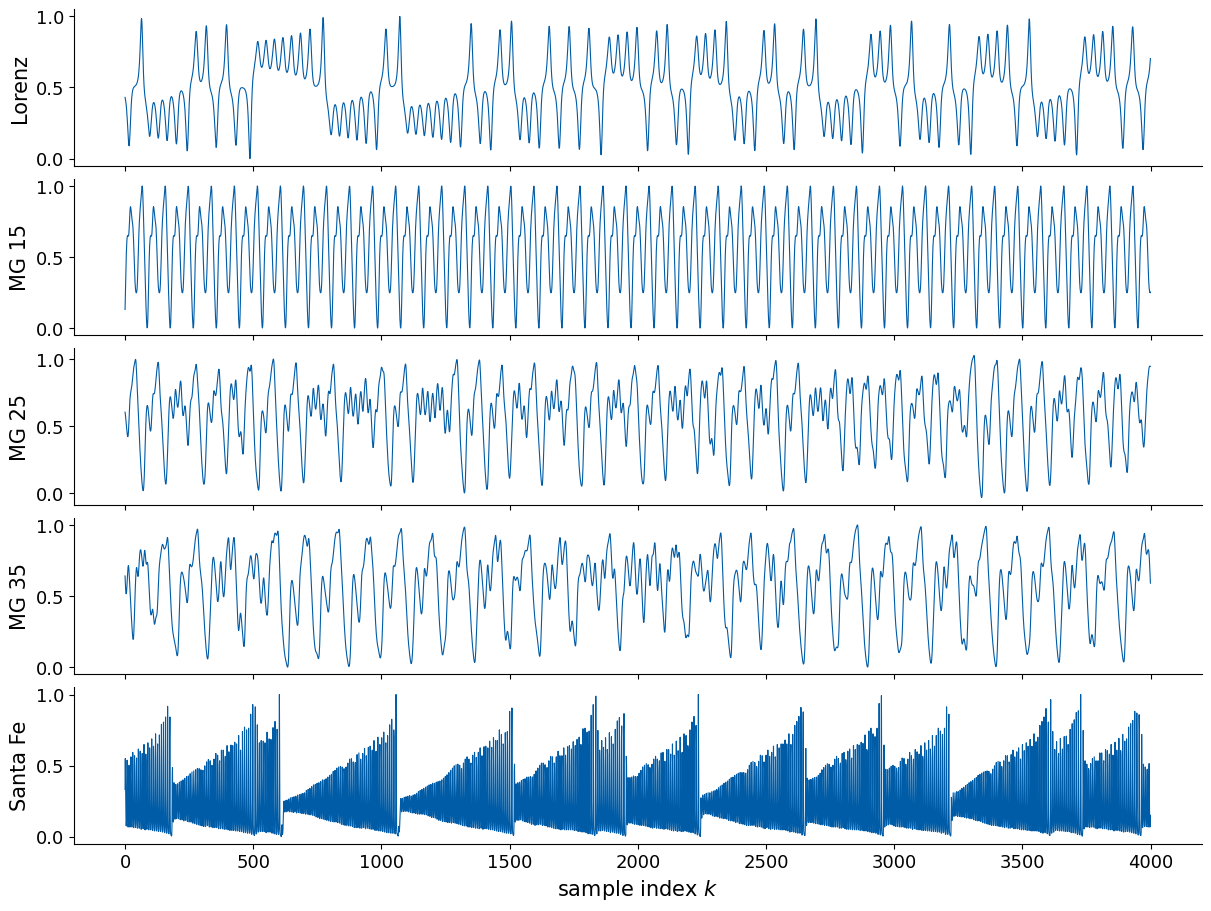

In [3]:
raw = {"Lorenz": np.asarray(lorenz_trajectory(N_SAMPLES)[:, 0]),
       "MG 15": mackey_glass(15, N_SAMPLES), "MG 25": mackey_glass(25, N_SAMPLES),
       "MG 35": mackey_glass(35, N_SAMPLES), "Santa Fe": santafe()[:N_SAMPLES]}
sig = {name: rescale01(s) for name, s in raw.items()}     # each signal rescaled with its training block
NAMES = list(sig)
for name, s in sig.items():
    assert s.shape == (N_SAMPLES,)
    print(f"{name:9s} train range [{s[:N_TRAIN].min():.2f}, {s[:N_TRAIN].max():.2f}]"
          f"   test range [{s[N_TRAIN:].min():.3f}, {s[N_TRAIN:].max():.3f}]")

fig, axs = plt.subplots(5, 1, figsize=(12, 9), sharex=True, layout="constrained")
for ax, name in zip(axs, NAMES):
    ax.plot(sig[name], lw=0.8, color=UJBlue)
    ax.set_ylabel(name)
axs[-1].set_xlabel("sample index $k$")
plt.show()

The ReservoirPy library [N. Trouvain *et al.*, ICANN 2020, [doi:10.1007/978-3-030-61616-8_40](https://doi.org/10.1007/978-3-030-61616-8_40)] ships generators of the same systems and the Santa Fe record. Its Santa Fe file is the same data. Its Mackey–Glass generator uses an RK4 step $h=1$ with the delayed value held fixed during a step and a random initial history around $x_0=1.2$, and its Lorenz generator calls `scipy.integrate.solve_ivp` without removing the transient. The trajectories therefore differ from ours in detail, and the signals are of the same kind. The helper `to_forecasting` cuts a series into input–target pairs $(s_k, s_{k+\tau})$.

ReservoirPy Santa Fe: (10093,) | max |difference| to our record: 0.0
ReservoirPy MG 25: range [0.256, 1.381]   ours: [0.248, 1.384]
ReservoirPy Lorenz x: range [-18.10, 19.53]   ours: [-18.08, 17.92]
to_forecasting(s, forecast=5): (3995, 1) (3995, 1) with Y[k] = s[k+5]


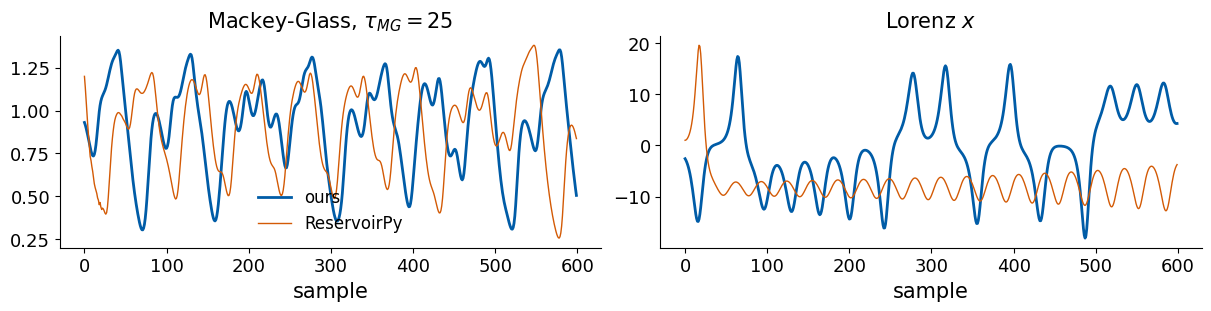

In [4]:
from reservoirpy.datasets import mackey_glass as rpy_mackey_glass, lorenz as rpy_lorenz
from reservoirpy.datasets import santafe_laser as rpy_santafe, to_forecasting

sf_rpy = rpy_santafe()[:, 0]                       # the Santa Fe record shipped with ReservoirPy, shape (10093,)
print("ReservoirPy Santa Fe:", sf_rpy.shape, "| max |difference| to our record:",
      np.abs(sf_rpy[:N_SAMPLES] - raw["Santa Fe"]).max())
mg_rpy = rpy_mackey_glass(N_SAMPLES, tau=25)[:, 0]    # RK4 with step h = 1, random history around x0 = 1.2
lz_rpy = rpy_lorenz(N_SAMPLES, h=0.02)[:, 0]          # scipy solve_ivp, samples every 0.02, no transient removed
print(f"ReservoirPy MG 25: range [{mg_rpy.min():.3f}, {mg_rpy.max():.3f}]   ours: [{raw['MG 25'].min():.3f}, {raw['MG 25'].max():.3f}]")
print(f"ReservoirPy Lorenz x: range [{lz_rpy.min():.2f}, {lz_rpy.max():.2f}]   ours: [{raw['Lorenz'].min():.2f}, {raw['Lorenz'].max():.2f}]")

# to_forecasting turns a series into input/target pairs (x_k, x_{k+tau})
Xin, Yout = to_forecasting(sig["Santa Fe"][:, None], forecast=5)
assert np.allclose(Yout[:, 0], sig["Santa Fe"][5:]) and np.allclose(Xin[:, 0], sig["Santa Fe"][:-5])
print("to_forecasting(s, forecast=5):", Xin.shape, Yout.shape, "with Y[k] = s[k+5]")

fig, axs = plt.subplots(1, 2, figsize=(12, 3), layout="constrained")
axs[0].plot(raw["MG 25"][:600], color=UJBlue, label="ours"); axs[0].plot(mg_rpy[:600], color=DSOrange, lw=1, label="ReservoirPy")
axs[0].set(title="Mackey-Glass, $\\tau_{MG}=25$", xlabel="sample"); axs[0].legend()
axs[1].plot(raw["Lorenz"][:600], color=UJBlue); axs[1].plot(lz_rpy[:600], color=DSOrange, lw=1)
axs[1].set(title="Lorenz $x$", xlabel="sample")
plt.show()

<hr/>
## 1. The forecasting task

Let $s_k$, $k = 0, 1, \dots, N-1$, be a scalar signal sampled at equal time steps. At the present time $k$ we know $s_0, \dots, s_k$ and we want $s_{k+\tau}$, where the integer $\tau \ge 1$ is the forecast horizon measured in samples. A predictor uses a window of the last $L$ values, the vector

$$\mathbf u_k = (s_k,\ s_{k-1},\ \dots,\ s_{k-L+1}) \in \mathbb R^L,$$

and returns $\hat s_{k+\tau} = G_\tau(\mathbf u_k)$. The window length $L$ is a model parameter. A window of past values can take the place of the unobserved state of the dynamical system, and the delay embedding (Takens theorem), discussed with the analysis of the signals, states the conditions under which it does. We choose $L$ by how well the forecasts work.

A forecast of $\tau$ steps can be produced in three ways. The one-step forecast predicts only $\hat s_{k+1} = G(\mathbf u_k)$. The direct forecast trains a separate map $G_\tau$ for every horizon, each from the true window $\mathbf u_k$. The recursive forecast, or free run, trains only the one-step map and iterates it, so that the prediction $\hat s_{k+1}$ enters the window from which $\hat s_{k+2}$ is computed, and so on. The recursive forecast turns the predictor into a dynamical system of its own, and its errors accumulate over the iterations. The direct forecast avoids this feedback at the price of one model per horizon.

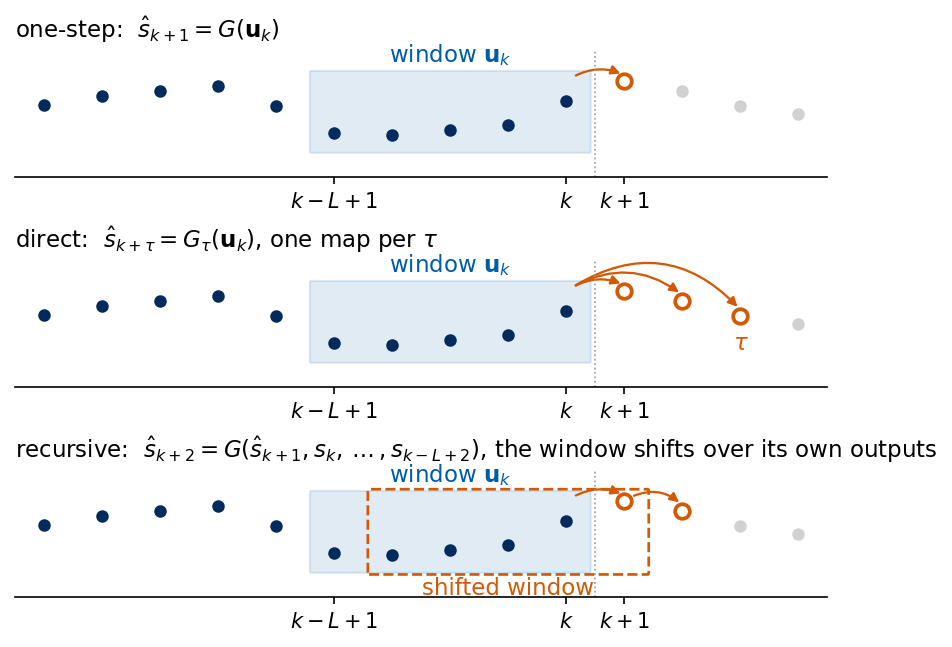

In [5]:
def draw_forecasting_modes(L=5, tau=3, width=5.5, height=4.2):
    """Schematic of one-step, direct and recursive forecasting on a short toy sequence.
    Each row: known samples (filled dots), the history window of L samples (shaded box),
    predicted samples (open orange dots) and arrows from the window to what is predicted."""
    k = 9                                              # index of the newest known sample s_k
    t = np.arange(k + tau + 2)
    y = 0.5 + 0.32 * np.sin(0.75 * t) + 0.08 * np.cos(1.9 * t)    # smooth toy signal
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(3, 1, figsize=(width, height), layout="constrained")
        titles = ["one-step:  $\\hat s_{k+1}=G(\\mathbf{u}_k)$",
                  "direct:  $\\hat s_{k+\\tau}=G_\\tau(\\mathbf{u}_k)$, one map per $\\tau$",
                  "recursive:  $\\hat s_{k+2}=G(\\hat s_{k+1}, s_k, \\dots, s_{k-L+2})$, the window shifts over its own outputs"]
        for row, ax in enumerate(axs):
            ax.plot(t[:k + 1], y[:k + 1], "o", color=UJNavy, ms=5, zorder=3)          # known past
            ax.plot(t[k + 1:], y[k + 1:], "o", color="0.82", ms=5, zorder=2)          # unknown future
            # history window u_k = (s_k, ..., s_{k-L+1}) as a shaded box
            ax.add_patch(FancyBboxPatch((k - L + 0.6, 0.02), L - 0.2, 0.96, boxstyle="round,pad=0.02",
                                        fc=UJBlue, alpha=0.12, ec=UJBlue, lw=1))
            ax.text(k - L / 2 + 0.5, 1.04, "window $\\mathbf{u}_k$", ha="center", va="bottom", color=UJBlue)
            ax.axvline(k + 0.5, color="0.6", lw=0.8, ls=":")                            # present time
            if row == 0:                                   # one step ahead
                targets = [k + 1]
            elif row == 1:                                 # direct: separate maps for each horizon
                targets = [k + 1, k + 2, k + tau]
            else:                                          # recursive: the window shifts and contains s_hat_{k+1}
                targets = [k + 1, k + 2]
                ax.add_patch(FancyBboxPatch((k - L + 1.6, 0.0), L - 0.2, 1.0, boxstyle="round,pad=0.02",
                                            fc="none", ec=DSOrange, lw=1.3, ls="--"))
                ax.text(k - L / 2 + 1.5, -0.04, "shifted window", ha="center", va="top", color=DSOrange)
            for j, kt in enumerate(targets):
                ax.plot(kt, y[kt], "o", mfc="white", mec=DSOrange, mew=1.8, ms=7, zorder=4)
                start = k + 0.1 if (row < 2 or j == 0) else k + 1.1     # arrow from the (shifted) window
                ax.add_patch(FancyArrowPatch((start, 0.92), (kt, y[kt] + 0.07), arrowstyle="-|>",
                                             mutation_scale=9, color=DSOrange, lw=1.1,
                                             connectionstyle=f"arc3,rad={-0.25 - 0.08 * j}"))
            if row == 1:
                ax.text(k + tau, y[k + tau] - 0.2, "$\\tau$", ha="center", va="top", color=DSOrange)
            ax.set_title(titles[row], loc="left")
            ax.set_xlim(-0.5, t[-1] + 0.5); ax.set_ylim(-0.3, 1.25)
            ax.set_yticks([]); ax.spines["left"].set_visible(False)
            ax.set_xticks([k - L + 1, k, k + 1]); ax.set_xticklabels(["$k-L+1$", "$k$", "$k+1$"])
    return fig

fig = draw_forecasting_modes()
save(fig, "fig_forecasting_modes"); plt.show()

<hr/>
## 2. Chronological split and rescaling

A model is fitted on one part of the record and judged on another. For a time series the parts must follow the order of time. The first 2500 samples form the training block, the next 500 the validation block on which we choose model orders and regularisation, and the last 1000 the test block, which is used only for the final scores. The rescaling to $[0,1]$ is fitted on the first 3000 samples, the training and validation blocks together, and applied unchanged to the test block, so that no property of the future enters the model. Test values may therefore lie slightly outside $[0,1]$.

Santa Fe rescaling from the training block: s = (x - 2) / (255 - 2)
test block after this rescaling: min 0.004, max 1.000


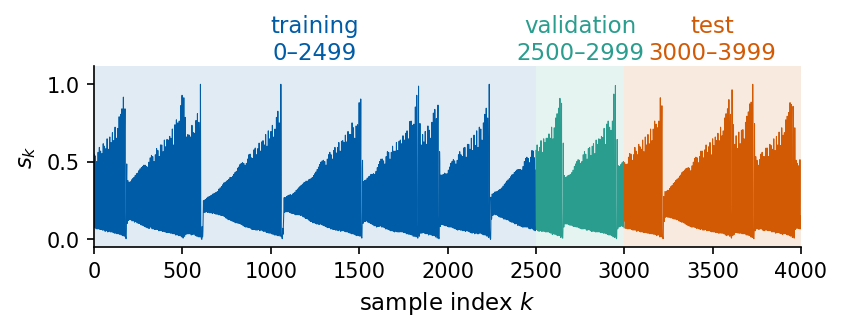

In [6]:
lo, hi = raw["Santa Fe"][:N_TRAIN].min(), raw["Santa Fe"][:N_TRAIN].max()
print(f"Santa Fe rescaling from the training block: s = (x - {lo:.0f}) / ({hi:.0f} - {lo:.0f})")
print(f"test block after this rescaling: min {sig['Santa Fe'][N_TRAIN:].min():.3f}, "
      f"max {sig['Santa Fe'][N_TRAIN:].max():.3f}")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.1), layout="constrained")
    blocks = [(0, N_TRAIN - N_VAL, "training", UJBlue), (N_TRAIN - N_VAL, N_TRAIN, "validation", "#2A9D8F"),
              (N_TRAIN, N_SAMPLES, "test", DSOrange)]
    for a, b, label, col in blocks:
        ax.axvspan(a, b, color=col, alpha=0.12, lw=0)
        ax.plot(np.arange(a, b), sig["Santa Fe"][a:b], color=col, lw=0.5)
        ax.text((a + b) / 2, 1.13, f"{label}\n{a}–{b - 1}", ha="center", va="bottom", color=col)
    ax.set_xlim(0, N_SAMPLES); ax.set_ylim(-0.05, 1.12)
    ax.set_xlabel("sample index $k$"); ax.set_ylabel("$s_k$")
    save(fig, "fig_split"); plt.show()

Shuffling the windows before the split, as one would do with independent images, puts the future into the training data. A window $\mathbf u_{k'}$ that starts after a test origin $k$ contains the later samples of the record as inputs, among them the test target $s_{k+\tau}$ itself whenever $k'-L < k+\tau \le k'$. A flexible model can then learn the test targets from the training inputs. We count how often this happens for windows of length $L=8$ and horizon $\tau=25$, once for the chronological split and once for a random split with the same number of test windows.

In [7]:
def delay_vectors(s, origins, L, stride=1):
    """Rows u_k = (s_k, s_{k-stride}, ..., s_{k-(L-1) stride}) for every origin k; shape (len(origins), L)."""
    return s[np.asarray(origins)[:, None] - stride * np.arange(L)[None, :]]

L_LK, TAU_LK = 8, 25
orig_all = np.arange(300, N_SAMPLES - TAU_MAX)              # all usable origins k
n_test = np.sum(orig_all >= N_TRAIN)

def leaked_fraction(train_orig, test_orig):
    """Fraction of test targets s_{k+tau} whose value enters some training window as an input."""
    seen = np.zeros(N_SAMPLES, bool)
    seen[(train_orig[:, None] - np.arange(L_LK)[None, :]).ravel()] = True     # samples inside training windows
    return np.mean(seen[test_orig + TAU_LK])

chrono_train = orig_all[orig_all + TAU_LK < N_TRAIN]           # targets inside the training block
chrono_test = orig_all[orig_all >= N_TRAIN]
perm = np.random.default_rng(0).permutation(orig_all)          # shuffled split of the same windows
shuf_test, shuf_train = perm[:n_test], perm[n_test:]
nums["leak_frac_chrono"] = float(leaked_fraction(chrono_train, chrono_test))
nums["leak_frac_shuffled"] = float(leaked_fraction(shuf_train, shuf_test))
print(f"window L = {L_LK}, horizon tau = {TAU_LK}, {n_test} test windows")
print(f"  test targets that are inputs of training windows, chronological split: {nums['leak_frac_chrono']:.3f}")
print(f"  test targets that are inputs of training windows, shuffled split     : {nums['leak_frac_shuffled']:.3f}")


window L = 8, horizon tau = 25, 950 test windows
  test targets that are inputs of training windows, chronological split: 0.000
  test targets that are inputs of training windows, shuffled split     : 0.997


With the chronological split no test target is ever an input of a training window. With the shuffled split almost every test target is. A score measured on such a split says how well the model interpolates inside a record it has partly seen, which is a different and much easier task than forecasting.

<hr/>
## 3. Scores

We score the predictions $\hat y_i$ of $n$ test targets $y_i$ at a fixed horizon $\tau$ by the Pearson correlation $r$ between predictions and targets and by its square, the capacity $C$,

$$r(\tau) = \frac{\sum_i (\hat y_i-\bar{\hat y})(y_i-\bar y)}{\sqrt{\sum_i (\hat y_i-\bar{\hat y})^2\,\sum_i (y_i-\bar y)^2}}, \qquad C(\tau) = r(\tau)^2 ,$$

where $\bar y$ and $\bar{\hat y}$ are the means of the targets and of the predictions. The capacity is the fraction of the target variance explained by the best affine function $a\hat y_i + b$ of the prediction. Summed over the horizons we get the total capacity and the skill horizon

$$C_{\rm tot} = \sum_{\tau=1}^{50} C(\tau), \qquad \tau_{1/2} = \min\{\tau : C(\tau) < 0.5\}.$$

$C_{\rm tot}$ lies between 0 and 50, and $\tau_{1/2}$ is the first horizon at which less than half of the target variance is explained. A predictor that returns a constant has no correlation with the targets, and we set $r=0$ for it.


In [8]:
@jax.jit
def scores(y_hat, y):
    """Scores of predictions y_hat (n,) against targets y (n,): Pearson r and capacity C = r^2.
    A constant prediction has no correlation with anything; we set r = 0 for it."""
    yc, hc = y - y.mean(), y_hat - y_hat.mean()
    den = jnp.sqrt(jnp.sum(yc ** 2) * jnp.sum(hc ** 2))
    r = jnp.where(den > 0, jnp.sum(yc * hc) / jnp.where(den > 0, den, 1.0), 0.0)
    return {"r": r, "C": r ** 2}

# all horizons at once: columns of (n_origins, TAU_MAX) arrays of predictions and targets
scores_all = jax.jit(jax.vmap(scores, in_axes=(1, 1)))

def c_tot(C):
    """Total capacity: sum of C(tau) over tau = 1..TAU_MAX."""
    return float(np.sum(C))

def tau_half(C):
    """Skill horizon: the first tau with C(tau) < 0.5; None if C stays above 0.5 up to TAU_MAX."""
    below = np.flatnonzero(np.asarray(C) < 0.5)
    return int(below[0] + 1) if below.size else None

def fmt_tau_half(C):
    th = tau_half(C)
    return f">{TAU_MAX}" if th is None else str(th)


In [9]:
rng = np.random.default_rng(1)
y = sig["Santa Fe"][N_TRAIN:]
y_hat = y + 0.1 * rng.standard_normal(y.shape)            # a noisy test predictor
sc = {k: float(v) for k, v in scores(jnp.asarray(y_hat), jnp.asarray(y)).items()}
r_scipy = scipy.stats.pearsonr(y_hat, y).statistic
# C as the explained-variance fraction of the least-squares line y ~ a y_hat + b
a_ls, b_ls = np.polyfit(y_hat, y, 1)
r2_line = 1 - np.sum((y - a_ls * y_hat - b_ls) ** 2) / np.sum((y - y.mean()) ** 2)
print(f"JAX   : r {sc['r']:.6f}  C {sc['C']:.6f}")
print(f"scipy.stats.pearsonr : r {r_scipy:.6f}")
print(f"least-squares line y = {a_ls:.4f} y_hat + {b_ls:.4f}: explained variance fraction {r2_line:.6f}")
assert abs(sc["r"] - r_scipy) < 1e-12 and abs(sc["C"] - r2_line) < 1e-12


JAX   : r 0.900692  C 0.811246
scipy.stats.pearsonr : r 0.900692
least-squares line y = 0.8136 y_hat + 0.0469: explained variance fraction 0.811246


The JAX value of $r$ agrees with `scipy.stats.pearsonr` to machine precision, and $C$ equals the fraction of the target variance explained by the least-squares line $y \approx a\hat y + b$. This line absorbs any scale and offset of the forecast. We compare three predictions of the Santa Fe test samples with the targets to see the consequences of this invariance.


$\hat y=y+\xi$           r = +0.901   C = 0.811
$\hat y=0.5\,y+0.3$      r = +1.000   C = 1.000
$\hat y=1-y$             r = -1.000   C = 1.000


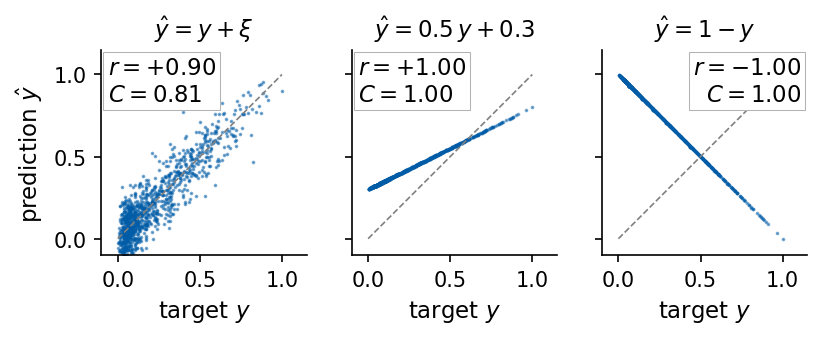

In [10]:
# three predictors of the same Santa Fe test targets y
preds = {"$\\hat y=y+\\xi$": y_hat,                        # noisy, unbiased; xi ~ N(0, 0.1^2)
         "$\\hat y=0.5\\,y+0.3$": 0.5 * y + 0.3,           # shape right, scale and offset wrong
         "$\\hat y=1-y$": 1.0 - y}                          # anticorrelated
demo = {}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.15), layout="constrained", sharex=True, sharey=True)
    for ax, (label, p) in zip(axs, preds.items()):
        sc = {k: float(v) for k, v in scores(jnp.asarray(p), jnp.asarray(y)).items()}
        demo[label] = sc
        ax.plot(y, p, ".", ms=1.5, color=UJBlue, alpha=0.5)
        ax.plot([0, 1], [0, 1], color="0.5", lw=0.8, ls="--")
        ax.set_title(label)
        # put the numbers in a corner without points: upper left, lower right, lower left
        x0, y0, ha, va = [(0.03, 0.97, "left", "top"), (0.03, 0.97, "left", "top"),
                          (0.97, 0.97, "right", "top")][list(preds).index(label)]
        ax.text(x0, y0, f"$r={sc['r']:+.2f}$\n$C={sc['C']:.2f}$", transform=ax.transAxes, va=va, ha=ha,
                bbox=dict(facecolor="white", edgecolor="0.7", pad=2.0, lw=0.5))
        ax.set_xlabel("target $y$"); ax.set_aspect("equal")
    axs[0].set_ylabel("prediction $\\hat y$")
    ax.set_xlim(-0.1, 1.15); ax.set_ylim(-0.1, 1.15)
    save(fig, "fig_capacity_demo"); plt.show()
for label, sc in demo.items():
    print(f"{label:24s} r = {sc['r']:+.3f}   C = {sc['C']:.3f}")
nums["demo_scaled"] = demo["$\\hat y=0.5\\,y+0.3$"]
nums["demo_noisy"] = demo["$\\hat y=y+\\xi$"]
nums["demo_anti"] = demo["$\\hat y=1-y$"]


The affine prediction $0.5\,y+0.3$ has half the amplitude of the signal and a wrong offset, and its capacity is $C=1$. Both $r$ and $C$ are unchanged under $\hat y \to a\hat y + b$ with $a>0$, and for $a<0$ the correlation $r$ changes sign while $C$ stays the same. The prediction $1-y$ moves against the target and therefore also has $C=1$, with $r=-1$. The noisy prediction scatters around the diagonal and has the smallest capacity of the three, $C=0.81$. The capacity thus measures how much of the target variance can be recovered from the forecast by a linear rescaling. The amplitude, the offset and the sign of the forecast as it stands are invisible to it, so we check them separately, with the sign of $r$ and with scatter plots of the forecast against the target.


All multi-step forecasts are scored on the same set of origins. A forecast made at time $k$ predicts $s_{k+1},\dots,s_{k+50}$, so we collect the predictions in an array of shape (number of origins, 50). The test origins are $k = 3000,\dots,3949$, so every target lies in the test block. Models are fitted on origins whose targets lie in the training block. For model selection the fit stops before the validation block and the scores are computed on the validation origins. The first origin is $k=260$, so that the longest window, which reaches 248 samples into the past, fits into the record.

In [11]:
K0 = 260                                                     # first usable origin: the longest window reaches 248 samples back
ORIG_FIT_VAL = np.arange(K0, N_TRAIN - N_VAL - TAU_MAX)      # fit for model selection: targets before validation
ORIG_VAL = np.arange(N_TRAIN - N_VAL, N_TRAIN - TAU_MAX)     # validation origins: targets inside the validation block
ORIG_FIT = np.arange(K0, N_TRAIN - TAU_MAX)                  # final fit: targets inside the training block
ORIG_TEST = np.arange(N_TRAIN, N_SAMPLES - TAU_MAX)          # test origins: targets inside the test block
TAUS = np.arange(1, TAU_MAX + 1)

def target_matrix(s, origins):
    """Y[i, tau-1] = s_{k_i + tau} for tau = 1..TAU_MAX; shape (len(origins), TAU_MAX)."""
    return s[np.asarray(origins)[:, None] + TAUS[None, :]]

def evaluate(pred, s, origins=ORIG_TEST):
    """C(tau) and r(tau) of a prediction array (len(origins), TAU_MAX)."""
    out = scores_all(jnp.asarray(pred), jnp.asarray(target_matrix(s, origins)))
    return {k: np.asarray(v) for k, v in out.items()}

print(f"origins: fit for selection {ORIG_FIT_VAL[0]}..{ORIG_FIT_VAL[-1]}, validation {ORIG_VAL[0]}..{ORIG_VAL[-1]}, "
      f"final fit {ORIG_FIT[0]}..{ORIG_FIT[-1]}, test {ORIG_TEST[0]}..{ORIG_TEST[-1]} ({len(ORIG_TEST)} origins)")

origins: fit for selection 260..2449, validation 2500..2949, final fit 260..2949, test 3000..3949 (950 origins)


<hr/>
## 4. Baselines

Two predictors need no fitting. Persistence repeats the last known value, $\hat s_{k+\tau} = s_k$. The mean predictor returns the mean of the training block for every horizon. A model is useful only where it beats both. For persistence $r(\tau)$ is close to the ACF $\rho(\tau)$ of the signal (it would be equal for an infinitely long record), so its capacity decays like $\rho(\tau)^2$. We compare $C(\tau)$ of persistence on the test origins with the squared sample ACF of the test block, $\rho(\tau)^2$ with $\rho(\tau) = \sum_k (s_k-\bar s)(s_{k+\tau}-\bar s)\big/\sum_k (s_k-\bar s)^2$.

signal    | persistence: C_tot  (r<0 part)  tau_1/2   C(1)    C(50)  max|C - rho^2| | mean: C_tot
Lorenz    |              8.35  ( 0.00)         8  0.9878   0.002     0.008      | 0.0
MG 15     |             19.54  ( 8.32)         6  0.9761   0.370     0.042      | 0.0
MG 25     |             13.26  ( 6.27)         8  0.9866   0.059     0.028      | 0.0
MG 35     |             11.85  ( 2.82)        10  0.9909   0.127     0.019      | 0.0
Santa Fe  |              5.45  ( 2.64)         1  0.2690   0.000     0.031      | 0.0


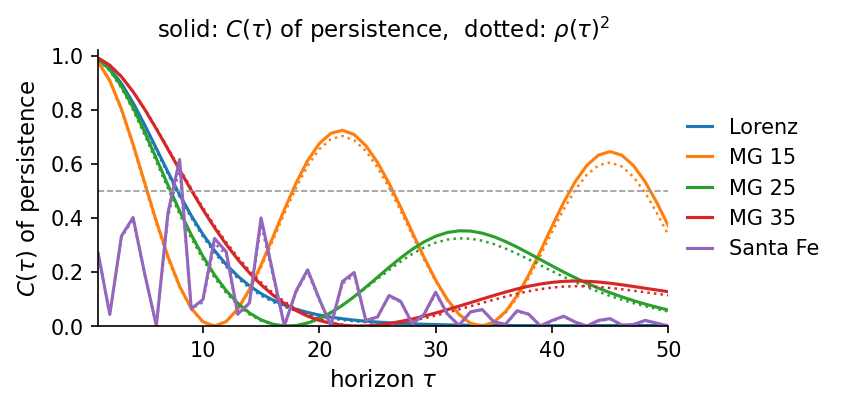

In [12]:
RES = {name: {} for name in NAMES}          # RES[signal][model] = dict of C and r arrays over tau
RHO2 = {}                                    # squared sample ACF of the test block, rho(tau)^2
for name, s in sig.items():
    persistence = np.repeat(s[ORIG_TEST][:, None], TAU_MAX, axis=1)        # s_hat_{k+tau} = s_k
    mean_pred = np.full((len(ORIG_TEST), TAU_MAX), s[:N_TRAIN].mean())    # s_hat = mean of the training block
    RES[name]["persistence"] = evaluate(persistence, s)
    RES[name]["mean"] = evaluate(mean_pred, s)
    RHO2[name] = acf(s[N_TRAIN:], nlags=TAU_MAX, fft=False)[1:] ** 2

print(f"{'signal':9s} | persistence: C_tot  (r<0 part)  tau_1/2   C(1)    C(50)  max|C - rho^2| | mean: C_tot")
for name in NAMES:
    P, M = RES[name]["persistence"], RES[name]["mean"]
    print(f"{name:9s} |            {c_tot(P['C']):6.2f}  ({c_tot(P['C'][P['r'] < 0]):5.2f})    {fmt_tau_half(P['C']):>6s}  {P['C'][0]:6.4f}  "
          f"{P['C'][-1]:6.3f}  {np.abs(P['C'] - RHO2[name]).max():8.3f}      | {c_tot(M['C']):.1f}")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.6), layout="constrained")
    for j, name in enumerate(NAMES):
        col = plt.get_cmap("tab10")(j)
        ax.plot(TAUS, RES[name]["persistence"]["C"], color=col, label=name)
        ax.plot(TAUS, RHO2[name], color=col, ls=":", lw=1.2)
    ax.axhline(0.5, color="0.6", lw=0.8, ls="--")
    ax.set(xlabel="horizon $\\tau$", ylabel="$C(\\tau)$ of persistence", ylim=(0, 1.02), xlim=(1, TAU_MAX))
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.2)
    ax.set_title("solid: $C(\\tau)$ of persistence,  dotted: $\\rho(\\tau)^2$")
    save(fig, "fig_baselines_capacity"); plt.show()
for name in NAMES:
    nums.setdefault("Ctot", {}).setdefault(name, {})["persistence"] = c_tot(RES[name]["persistence"]["C"])
    nums.setdefault("tau_half", {}).setdefault(name, {})["persistence"] = tau_half(RES[name]["persistence"]["C"])
    P = RES[name]["persistence"]
    nums.setdefault("Ctot_negative_r", {}).setdefault(name, {})["persistence"] = c_tot(P["C"][P["r"] < 0])


Persistence is a strong forecast at short horizons for the smooth signals, with $C(1)$ between 0.976 and 0.991, and a weak one for the Santa Fe laser, whose intensity changes from a minimum to a maximum within a few samples ($C(1)=0.27$ and $\tau_{1/2}=1$). On every signal its $C(\tau)$ stays within 0.042 of $\rho(\tau)^2$. On the Mackey–Glass signals $C(\tau)$ of persistence oscillates, because $\rho(\tau)$ swings to negative values and returns towards 1 after about one oscillation period. At the negative swings persistence is anticorrelated with the target, and the squared correlation counts this as skill. On MG 15 these horizons contribute 8.32 of the total $C_{\rm tot}=19.54$, on MG 25 6.27 of 13.26, and on Santa Fe 2.64 of 5.45. The mean predictor is a constant, so by our convention it has $C=0$ at every horizon and $C_{\rm tot}=0$.


<hr/>
## 5. Autoregressive models

### The AR(p) model

The autoregressive model of order $p$ writes the next value as a linear combination of the last $p$ values plus a random innovation [Box *et al.*, *Time Series Analysis: Forecasting and Control*, 5th ed., Wiley (2015)],

$$s_k = c + \phi_1 s_{k-1} + \phi_2 s_{k-2} + \dots + \phi_p s_{k-p} + \varepsilon_k ,$$

where $c$ is a constant, $\phi_1,\dots,\phi_p$ are the AR coefficients and $\varepsilon_k$ is white noise with variance $\sigma^2$. The coefficients follow from least squares. For target times $t = p,\dots,n-1$ we stack the rows $(1, s_{t-1},\dots,s_{t-p})$ into the design matrix $X$ of shape $(n-p, p+1)$ and the targets into $\mathbf y$, and solve

$$\hat{\boldsymbol\beta} = \arg\min_{\boldsymbol\beta}\ \|\mathbf y - X\boldsymbol\beta\|^2, \qquad X^\top X\,\hat{\boldsymbol\beta} = X^\top \mathbf y, \qquad \hat{\boldsymbol\beta} = (c, \phi_1,\dots,\phi_p).$$

The normal equations on the right are the simplest route. `jnp.linalg.lstsq` solves the same problem through an orthogonal factorisation, which is numerically safer when the columns of $X$ are nearly collinear, as neighbouring samples of a smooth signal are. `statsmodels.tsa.ar_model.AutoReg` uses the same conditional least squares.

In [13]:
def ar_design(s, p, t):
    """Rows [1, s_{t-1}, s_{t-2}, ..., s_{t-p}] for target times t; shape (len(t), p+1)."""
    t = np.asarray(t)
    return np.concatenate([np.ones((len(t), 1)), s[t[:, None] - np.arange(1, p + 1)[None, :]]], axis=1)

@jax.jit
def lstsq_fit(X, y):
    """Least squares by the normal equations (X^T X) beta = X^T y and by jnp.linalg.lstsq (QR/SVD)."""
    beta_normal = jnp.linalg.solve(X.T @ X, X.T @ y)
    beta_lstsq = jnp.linalg.lstsq(X, y)[0]
    return beta_normal, beta_lstsq

p_demo = 8
s = sig["Santa Fe"]
t_fit = np.arange(p_demo, N_TRAIN)                     # all targets of the training block
X, yv = ar_design(s, p_demo, t_fit), s[t_fit]
assert X.shape == (N_TRAIN - p_demo, p_demo + 1)
beta_n, beta_l = (np.asarray(b) for b in lstsq_fit(jnp.asarray(X), jnp.asarray(yv)))
sm = AutoReg(s[:N_TRAIN], lags=p_demo, trend="c").fit()          # statsmodels: same conditional least squares
print("AR(8) on Santa Fe, coefficients (c, phi_1, ..., phi_8)")
print("  JAX normal equations:", np.round(beta_n, 5))
print("  JAX lstsq           :", np.round(beta_l, 5))
print("  statsmodels AutoReg :", np.round(sm.params, 5))
nums["ar8_max_diff_statsmodels"] = float(np.max(np.abs(beta_n - sm.params)))
print(f"  max |JAX - statsmodels| = {nums['ar8_max_diff_statsmodels']:.1e}")

AR(8) on Santa Fe, coefficients (c, phi_1, ..., phi_8)
  JAX normal equations: [ 0.29174  0.49254 -0.6493   0.12742 -0.35852 -0.00873 -0.28929  0.34616
  0.06338]
  JAX lstsq           : [ 0.29174  0.49254 -0.6493   0.12742 -0.35852 -0.00873 -0.28929  0.34616
  0.06338]
  statsmodels AutoReg : [ 0.29174  0.49254 -0.6493   0.12742 -0.35852 -0.00873 -0.28929  0.34616
  0.06338]
  max |JAX - statsmodels| = 2.4e-14


The three estimates agree to about $10^{-12}$ or better.

### Order selection

The order $p$ must be chosen. A larger $p$ always lowers the residual variance on the training data, and beyond some order the extra coefficients fit noise. The Akaike information criterion (AIC) [H. Akaike, IEEE Trans. Autom. Control **19**, 716 (1974), [doi:10.1109/TAC.1974.1100705](https://doi.org/10.1109/TAC.1974.1100705)] adds a penalty for every parameter,

$$\mathrm{AIC} = -2\ln\mathcal L + 2 n_{\rm par}, \qquad -2\ln\mathcal L = n\ln(2\pi\hat\sigma^2) + n,$$

where $\mathcal L$ is the maximised Gaussian likelihood of the $n$ residuals with variance $\hat\sigma^2$ and $n_{\rm par} = p+2$ counts $c$, the $\phi_i$ and $\sigma^2$. All orders are compared on the same samples $t = 40,\dots,2999$. The alternative is the one-step capacity $C(1)$ on the validation block of a model fitted on the samples before it, and we take the order that maximises it. Near $C(1)=1$ we plot the unexplained fraction $1-C(1)$ on a logarithmic scale. We scan $p = 1,\dots,40$ for every signal.

Lorenz    p(AIC) = 38 (statsmodels ar_select_order: 38)   p(validation) = 40   validation 1 - C(1) at p(AIC) 1.27e-09, at p(validation) 1.27e-09   (at p = 10: 1.34e-08)
MG 15     p(AIC) = 40 (statsmodels ar_select_order: 40)   p(validation) = 40   validation 1 - C(1) at p(AIC) 4.10e-07, at p(validation) 4.10e-07   (at p = 10: 8.14e-07)
MG 25     p(AIC) = 37 (statsmodels ar_select_order: 37)   p(validation) = 26   validation 1 - C(1) at p(AIC) 2.77e-07, at p(validation) 2.76e-07   (at p = 10: 4.13e-07)
MG 35     p(AIC) = 40 (statsmodels ar_select_order: 40)   p(validation) = 40   validation 1 - C(1) at p(AIC) 3.59e-07, at p(validation) 3.59e-07   (at p = 10: 5.10e-07)
Santa Fe  p(AIC) = 38 (statsmodels ar_select_order: 38)   p(validation) = 14   validation 1 - C(1) at p(AIC) 1.81e-01, at p(validation) 1.78e-01   (at p = 10: 1.90e-01)


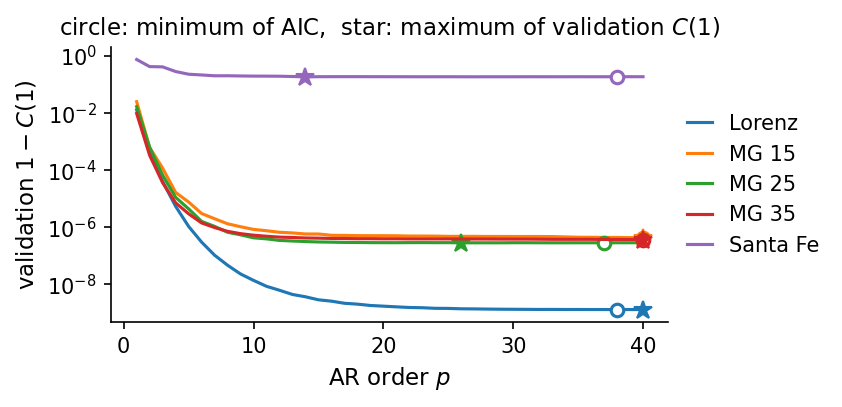

In [14]:
P_MAX = 40
P_GRID = np.arange(1, P_MAX + 1)

def ar_order_scan(s):
    """AIC(p) on the training block (common sample t = P_MAX..N_TRAIN-1, Gaussian likelihood) and
    one-step validation capacity C(1) of an AR(p) fitted on samples before the validation block."""
    t_aic = np.arange(P_MAX, N_TRAIN)
    t_fit = np.arange(P_MAX, N_TRAIN - N_VAL)
    t_val = np.arange(N_TRAIN - N_VAL, N_TRAIN)
    aic, val = [], []
    for p in P_GRID:
        X = ar_design(s, p, t_aic)
        beta = np.linalg.lstsq(X, s[t_aic], rcond=None)[0]
        n = len(t_aic)
        sigma2 = np.mean((s[t_aic] - X @ beta) ** 2)                       # ML estimate of the noise variance
        aic.append(n * np.log(2 * np.pi * sigma2) + n + 2 * (p + 2))     # -2 ln L + 2 n_par, n_par = p + 2
        beta_v = np.linalg.lstsq(ar_design(s, p, t_fit), s[t_fit], rcond=None)[0]
        val.append(float(scores(jnp.asarray(ar_design(s, p, t_val) @ beta_v), jnp.asarray(s[t_val]))["C"]))
    return np.array(aic), np.array(val)

AR_ORDER = {}
for name, s in sig.items():
    aic, val = ar_order_scan(s)
    p_aic, p_val = int(P_GRID[np.argmin(aic)]), int(P_GRID[np.argmax(val)])
    p_sm = ar_select_order(s[:N_TRAIN], maxlag=P_MAX, ic="aic", trend="c").ar_lags
    p_sm = int(max(p_sm)) if p_sm is not None and len(p_sm) else 0
    AR_ORDER[name] = dict(aic=aic, val=val, p_aic=p_aic, p_val=p_val, p_sm=p_sm)
    print(f"{name:9s} p(AIC) = {p_aic:2d} (statsmodels ar_select_order: {p_sm:2d})   p(validation) = {p_val:2d}"
          f"   validation 1 - C(1) at p(AIC) {1 - val[p_aic - 1]:.2e}, at p(validation) {1 - val[p_val - 1]:.2e}"
          f"   (at p = 10: {1 - val[9]:.2e})")
nums["ar_p_aic"] = {n: AR_ORDER[n]["p_aic"] for n in NAMES}
nums["ar_p_val"] = {n: AR_ORDER[n]["p_val"] for n in NAMES}
nums["ar_val_C1"] = {n: {"p_aic": float(AR_ORDER[n]["val"][AR_ORDER[n]["p_aic"] - 1]),
                         "p_val": float(AR_ORDER[n]["val"][AR_ORDER[n]["p_val"] - 1])} for n in NAMES}

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.6), layout="constrained")
    for j, name in enumerate(NAMES):
        col = plt.get_cmap("tab10")(j)
        o = AR_ORDER[name]
        ax.plot(P_GRID, 1 - o["val"], color=col, label=name)
        ax.plot(o["p_aic"], 1 - o["val"][o["p_aic"] - 1], "o", mfc="white", mec=col, mew=1.5, ms=6)
        ax.plot(o["p_val"], 1 - o["val"][o["p_val"] - 1], "*", color=col, ms=9)
    ax.set(xlabel="AR order $p$", ylabel="validation $1 - C(1)$", yscale="log")
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.2)
    ax.set_title("circle: minimum of AIC,  star: maximum of validation $C(1)$")
    save(fig, "fig_ar_order"); plt.show()


Our AIC minimum agrees with `ar_select_order` of `statsmodels` on every signal, and the AIC prefers orders between 37 and 40, at the end of the scanned range. On the smooth Lorenz and Mackey–Glass signals the one-step forecast leaves almost no error already at $p=10$, with a validation $1-C(1)$ of $1.3\times10^{-8}$ on Lorenz and between $4\times10^{-7}$ and $8\times10^{-7}$ on Mackey–Glass. The maximum of $C(1)$, at $p=40$ on Lorenz, MG 15 and MG 35 and at $p=26$ on MG 25, is therefore decided by differences in the seventh digit of $C$ or beyond. On Santa Fe the AIC picks $p=38$ and the validation capacity $p=14$, with almost the same one-step validation capacity ($C(1)=0.819$ and $0.822$). AIC assumes that the residuals are independent Gaussian noise. For deterministic signals the residuals are the part of the dynamics that a linear map cannot represent, and they are neither independent nor Gaussian, so the AIC order is a convention and need not be the optimal one. In what follows the recursive AR forecasts use the AIC order.

### Stationarity

An AR process has a stationary solution, with mean and correlations that do not change in time, when all roots of the characteristic polynomial

$$\Phi_p(z) = 1 - \phi_1 z - \phi_2 z^2 - \dots - \phi_p z^p$$

lie outside the unit circle $|z|=1$ [Box *et al.* (2015) and P. J. Brockwell and R. A. Davis, *Introduction to Time Series and Forecasting*, Springer (2016), [doi:10.1007/978-3-319-29854-2](https://doi.org/10.1007/978-3-319-29854-2)]. A root inside the circle makes the iterated model grow exponentially, and a root on the circle (a unit root) gives a random walk. The mean of a stationary AR process is $\mu = c/(1-\sum_i \phi_i)$.


Lorenz    AR(38): smallest |root| of Phi_p = 1.0341  (stationary: True)   sum(phi) = 1.0000
MG 15     AR(40): smallest |root| of Phi_p = 1.0036  (stationary: True)   sum(phi) = 0.9988
MG 25     AR(37): smallest |root| of Phi_p = 1.0123  (stationary: True)   sum(phi) = 0.9996
MG 35     AR(40): smallest |root| of Phi_p = 1.0147  (stationary: True)   sum(phi) = 0.9998
Santa Fe  AR(38): smallest |root| of Phi_p = 1.0180  (stationary: True)   sum(phi) = 0.1404


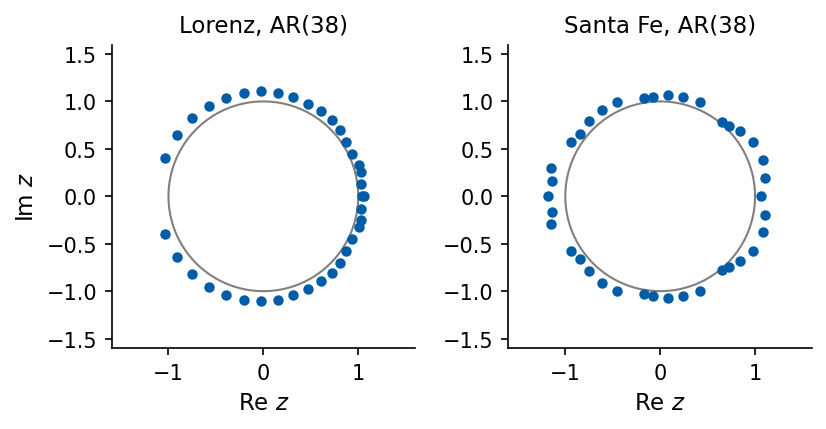

In [15]:
AR_FIT = {}                                        # AR(p_AIC) fitted on the whole training block
for name, s in sig.items():
    p = AR_ORDER[name]["p_aic"]
    t_fit = np.arange(P_MAX, N_TRAIN)
    beta = np.asarray(lstsq_fit(jnp.asarray(ar_design(s, p, t_fit)), jnp.asarray(s[t_fit]))[1])
    c, phi = beta[0], beta[1:]
    # roots of Phi_p(z) = 1 - phi_1 z - ... - phi_p z^p ; np.roots wants the highest power first
    roots = np.roots(np.concatenate([-phi[::-1], [1.0]]))
    AR_FIT[name] = dict(p=p, c=c, phi=phi, mu=c / (1 - phi.sum()), roots=roots)
    print(f"{name:9s} AR({p:2d}): smallest |root| of Phi_p = {np.abs(roots).min():.4f}  "
          f"(stationary: {np.all(np.abs(roots) > 1)})   sum(phi) = {phi.sum():.4f}")
nums["ar_min_root"] = {n: float(np.abs(AR_FIT[n]["roots"]).min()) for n in NAMES}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.75), layout="constrained")
    for ax, name in zip(axs, ["Lorenz", "Santa Fe"]):
        z = AR_FIT[name]["roots"]
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(np.cos(th), np.sin(th), color="0.5", lw=1)                     # unit circle
        ax.plot(z.real, z.imag, "o", color=UJBlue, ms=4)
        ax.set_aspect("equal"); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
        ax.set_title(f"{name}, AR({AR_FIT[name]['p']})")
        ax.set_xlabel("Re $z$")
    axs[0].set_ylabel("Im $z$")
    save(fig, "fig_ar_roots"); plt.show()

All fitted models are stationary, and their smallest root moduli lie between 1.004 (MG 15) and 1.034 (Lorenz), just outside the unit circle. A root $z_j = |z_j|e^{i\omega_j}$ contributes a mode $\propto |z_j|^{-k}\cos(\omega_j k)$ to the iterated forecast, so roots close to the circle are slowly decaying oscillations with frequency $\omega_j$. On the smooth signals the coefficients sum to almost 1 (between 0.9988 and 1.0000), which places a root near $z=1$ and makes the mean $\mu = c/(1-\sum_i\phi_i)$ sensitive to small changes of the coefficients. On Santa Fe the sum is 0.14 and the roots spread around the circle, following the fast pulsation.

<hr/>
## 6. Moving-average, ARMA and ARIMA models

### MA(q) and the Wold decomposition

The moving-average model of order $q$ builds the signal from the current and the last $q$ innovations,

$$s_k = \mu + \varepsilon_k + \theta_1\varepsilon_{k-1} + \dots + \theta_q\varepsilon_{k-q}.$$

The Wold decomposition theorem states that every covariance-stationary process splits into a part that is predicted without error by a linear function of its past and an infinite moving average of uncorrelated innovations [Box *et al.* (2015)]. MA(q) truncates this sum after $q$ terms. Its ACF follows directly from the definition. Two samples more than $q$ steps apart share no innovation, so $\rho(k) = 0$ for $k > q$. For MA(2),

$$\rho(1) = \frac{\theta_1 + \theta_1\theta_2}{1+\theta_1^2+\theta_2^2}, \qquad \rho(2) = \frac{\theta_2}{1+\theta_1^2+\theta_2^2}, \qquad \rho(k>2)=0 .$$

The ACF of an AR process instead decays gradually. For AR(2) it obeys the Yule–Walker recursion $\rho(k) = \phi_1\rho(k-1) + \phi_2\rho(k-2)$ with $\rho(1) = \phi_1/(1-\phi_2)$. We simulate MA(2) with $\boldsymbol\theta = (0.8, 0.4)$ and AR(2) with $\boldsymbol\phi = (0.5, 0.3)$ in JAX, $20\,000$ samples each with unit-variance Gaussian innovations. MA(2) is a convolution of the noise with $(1,\theta_1,\theta_2)$. AR(2) is a recursion, which we run with `lax.scan`.

max |JAX ACF - statsmodels acf|: 2.220446049250313e-16
MA(2) rho(1..4): sample [ 0.626  0.226 -0.002 -0.013]  exact [0.622 0.222 0.    0.   ]
AR(2) rho(1..4): sample [0.719 0.662 0.54  0.468]  exact [0.714 0.657 0.543 0.469]
95% band for the sample ACF of white noise: +-0.0139


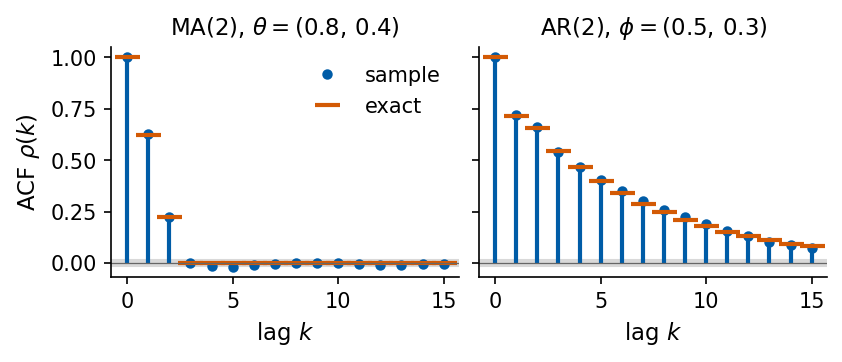

In [16]:
@partial(jax.jit, static_argnums=2)
def simulate_ma(theta, key, n):
    """MA(q): s_k = eps_k + theta_1 eps_{k-1} + ... + theta_q eps_{k-q}, eps ~ N(0, 1); returns (n,)."""
    q = theta.shape[0]
    eps = jax.random.normal(key, (n + q,))
    # s_k = sum_j theta_j eps_{k-j} with theta_0 = 1: a convolution of the noise with (1, theta_1, ..., theta_q)
    return jnp.convolve(eps, jnp.concatenate([jnp.ones(1), theta]), mode="valid")

@partial(jax.jit, static_argnums=2)
def simulate_ar(phi, key, n, burn=500):
    """AR(p): s_k = phi_1 s_{k-1} + ... + phi_p s_{k-p} + eps_k, eps ~ N(0, 1); first `burn` samples dropped."""
    p = phi.shape[0]
    eps = jax.random.normal(key, (n + burn,))
    def step(hist, e):                       # hist = (s_{k-1}, ..., s_{k-p})
        s_new = jnp.dot(phi, hist) + e
        return jnp.concatenate([s_new[None], hist[:-1]]), s_new
    _, s = jax.lax.scan(step, jnp.zeros(p), eps)
    return s[burn:]

def acf_jax(x, kmax):
    """Sample ACF rho(k) = sum_t (x_t - xbar)(x_{t+k} - xbar) / sum_t (x_t - xbar)^2, k = 0..kmax."""
    x = x - x.mean()
    n = x.shape[0]
    return jnp.array([jnp.dot(x[:n - k], x[k:]) for k in range(kmax + 1)]) / jnp.dot(x, x)

theta_ma = jnp.array([0.8, 0.4]); phi_ar = jnp.array([0.5, 0.3])
n_sim, KMAX = 20000, 15
s_ma = simulate_ma(theta_ma, jax.random.key(0), n_sim)
s_ar = simulate_ar(phi_ar, jax.random.key(1), n_sim)
rho_ma, rho_ar = np.asarray(acf_jax(s_ma, KMAX)), np.asarray(acf_jax(s_ar, KMAX))
print("max |JAX ACF - statsmodels acf|:", np.abs(rho_ma - acf(np.asarray(s_ma), nlags=KMAX, fft=False)).max())
# exact ACF of the MA(2) process: rho(1) = (th1 + th1 th2) / (1 + th1^2 + th2^2), rho(2) = th2 / (...), 0 beyond
th1, th2 = 0.8, 0.4
den = 1 + th1**2 + th2**2
rho_exact = np.array([1.0, (th1 + th1 * th2) / den, th2 / den] + [0.0] * (KMAX - 2))
# exact ACF of the AR(2) process from the Yule-Walker recursion rho(k) = phi_1 rho(k-1) + phi_2 rho(k-2)
ph1, ph2 = 0.5, 0.3
rho_ar_exact = [1.0, ph1 / (1 - ph2)]
for k in range(2, KMAX + 1):
    rho_ar_exact.append(ph1 * rho_ar_exact[-1] + ph2 * rho_ar_exact[-2])
rho_ar_exact = np.array(rho_ar_exact)
print("MA(2) rho(1..4): sample", np.round(rho_ma[1:5], 3), " exact", np.round(rho_exact[1:5], 3))
print("AR(2) rho(1..4): sample", np.round(rho_ar[1:5], 3), " exact", np.round(rho_ar_exact[1:5], 3))
print(f"95% band for the sample ACF of white noise: +-{1.96 / np.sqrt(n_sim):.4f}")
nums["ma2_rho1_exact"], nums["ma2_rho2_exact"] = float(rho_exact[1]), float(rho_exact[2])

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained", sharey=True)
    for ax, r, rex, title in [(axs[0], rho_ma, rho_exact, "MA(2), $\\theta=(0.8,\\,0.4)$"),
                              (axs[1], rho_ar, rho_ar_exact, "AR(2), $\\phi=(0.5,\\,0.3)$")]:
        k = np.arange(KMAX + 1)
        ax.vlines(k, 0, r, color=UJBlue, lw=2); ax.plot(k, r, "o", color=UJBlue, ms=4, label="sample")
        ax.plot(k, rex, "_", color=DSOrange, ms=12, mew=2, label="exact")
        ax.axhspan(-1.96 / np.sqrt(n_sim), 1.96 / np.sqrt(n_sim), color="0.85")
        ax.axhline(0, color="0.4", lw=0.6); ax.set_title(title); ax.set_xlabel("lag $k$")
    axs[0].set_ylabel("ACF $\\rho(k)$"); axs[0].legend(loc="upper right")
    save(fig, "fig_acf_ma_ar"); plt.show()

The sample ACF of MA(2) drops into the band $\pm 1.96/\sqrt n$ expected for uncorrelated samples after lag 2, while the AR(2) ACF decays over many lags. This contrast is the classical way to recognise the two models in data, a cut-off of the ACF for MA and a gradual decay for AR.

### Invertibility

Different MA models can have the same ACF. For MA(1), $\rho(1) = \theta/(1+\theta^2)$ is unchanged under $\theta \to 1/\theta$. Of each such pair we keep the invertible model, whose polynomial $\Theta_q(z) = 1 + \theta_1 z + \dots + \theta_q z^q$ has all roots outside the unit circle. Only for this model can the innovations be recovered from the past values, $\varepsilon_k = \Theta_q(B)^{-1} s_k$, which turns the MA model into a convergent AR($\infty$) model and makes its forecast computable.

In [17]:
# MA(1) with theta and with 1/theta: the same autocorrelation rho(1) = theta / (1 + theta^2)
for th in (0.5, 2.0):
    print(f"MA(1), theta = {th}: rho(1) = {th / (1 + th**2):.3f}, root of Theta(z) = 1 + theta z at z = {-1 / th:+.2f}")
# roots of Theta_2(z) = 1 + 0.8 z + 0.4 z^2 for the MA(2) above
r_ma = np.roots([0.4, 0.8, 1.0])
print("MA(2) roots of Theta(z):", np.round(r_ma, 3), "moduli", np.round(np.abs(r_ma), 3))
nums["ma2_root_modulus"] = float(np.abs(r_ma).min())

MA(1), theta = 0.5: rho(1) = 0.400, root of Theta(z) = 1 + theta z at z = -2.00
MA(1), theta = 2.0: rho(1) = 0.400, root of Theta(z) = 1 + theta z at z = -0.50
MA(2) roots of Theta(z): [-1.+1.225j -1.-1.225j] moduli [1.581 1.581]


The innovations of an MA model are not observed, so least squares on past values does not apply. `statsmodels` estimates $\theta_j$ by maximum likelihood with a Kalman filter, a recursion that updates the estimate of the unobserved quantities of the model with every new sample and so reconstructs the innovations. On the simulated MA(2) it recovers the true parameters within one standard error.

In [18]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    res_ma = ARIMA(np.asarray(s_ma), order=(0, 0, 2), trend="n").fit()
print("ARIMA(0,0,2) maximum-likelihood fit to the simulated MA(2):")
print("  theta_1, theta_2 =", np.round(res_ma.params[:2], 4), " sigma^2 =", round(float(res_ma.params[2]), 4),
      " (true 0.8, 0.4, 1)")
print("  standard errors  :", np.round(res_ma.bse[:2], 4))
nums["ma2_fit_theta"] = [float(v) for v in res_ma.params[:2]]

ARIMA(0,0,2) maximum-likelihood fit to the simulated MA(2):
  theta_1, theta_2 = [0.8024 0.397 ]  sigma^2 = 1.0038  (true 0.8, 0.4, 1)
  standard errors  : [0.0065 0.0065]


### ARMA(p,q) and the backshift operator

The backshift operator $B$ shifts a series by one sample, $B s_k = s_{k-1}$ and $B^m s_k = s_{k-m}$. With it the AR and MA polynomials act on the series, and the ARMA(p,q) model combining both reads

$$\Phi_p(B)\,s_k = c + \Theta_q(B)\,\varepsilon_k, \qquad \Phi_p(B) = 1-\sum_{i=1}^p \phi_i B^i, \qquad \Theta_q(B) = 1+\sum_{j=1}^q \theta_j B^j .$$

A few MA terms can replace many AR terms. An MA(1) component corresponds to an AR($\infty$) part with geometrically decaying coefficients, so ARMA models are often more economical than pure AR models.

### ARIMA(p,d,q) and differencing

ARMA models assume a stationary series. A series with a trend, or with a unit root, is first differenced. The difference operator $1-B$ gives $(1-B)s_k = s_k - s_{k-1}$, and ARIMA(p,d,q) applies an ARMA(p,q) model to the $d$-times differenced series,

$$\Phi_p(B)\,(1-B)^d\,s_k = c + \Theta_q(B)\,\varepsilon_k .$$

One difference turns a linear trend $a + bk$ into the constant $b$ and a random walk into white noise. We test this on the Lorenz signal with an added linear drift of $5\times10^{-4}$ per sample, fit ARIMA(4,0,0) with a constant and ARIMA(4,1,0) with a drift term on the training block, and forecast the whole test block from the last training sample.

mean of the series: first half of training 0.840, second half 1.636
mean of the first difference: first half 6.85e-04, second half 3.58e-04 (drift per sample 5e-04)
ARIMA(4,0,0): sum(phi) = 0.99986, fitted mean 1.238
ARIMA(4,1,0): drift estimate 5.22e-04 per sample


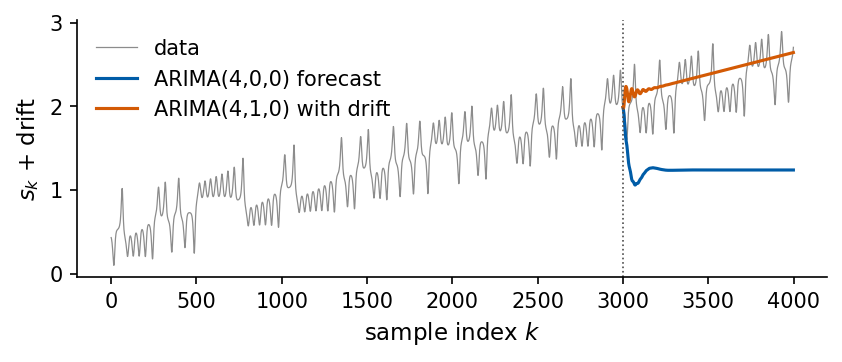

In [19]:
# Lorenz x (rescaled) plus a linear drift: a series whose mean changes in time
drift = 5e-4
s_tr = sig["Lorenz"] + drift * np.arange(N_SAMPLES)
H = N_SAMPLES - N_TRAIN                                  # forecast the whole test block from k = N_TRAIN - 1
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    res_arma_d = ARIMA(s_tr[:N_TRAIN], order=(4, 0, 0), trend="c").fit()
    res_arima_d = ARIMA(s_tr[:N_TRAIN], order=(4, 1, 0), trend="t").fit()   # with d = 1, trend "t" is a drift
f_arma = res_arma_d.forecast(H)
f_arima = res_arima_d.forecast(H)
half = N_TRAIN // 2
print(f"mean of the series: first half of training {s_tr[:half].mean():.3f}, second half {s_tr[half:N_TRAIN].mean():.3f}")
w = np.diff(s_tr[:N_TRAIN])
print(f"mean of the first difference: first half {w[:half].mean():.2e}, second half {w[half:].mean():.2e}"
      f" (drift per sample {drift:.0e})")
print(f"ARIMA(4,0,0): sum(phi) = {res_arma_d.arparams.sum():.5f}, fitted mean {res_arma_d.params[0]:.3f}")
print(f"ARIMA(4,1,0): drift estimate {res_arima_d.params[0]:.2e} per sample")
nums["drift_arma_sumphi"] = float(res_arma_d.arparams.sum())
nums["drift_arima_drift"] = float(res_arima_d.params[0])

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.3), layout="constrained")
    k = np.arange(N_SAMPLES)
    ax.plot(k, s_tr, color="0.55", lw=0.6, label="data")
    ax.plot(k[N_TRAIN:], f_arma, color=UJBlue, label="ARIMA(4,0,0) forecast")
    ax.plot(k[N_TRAIN:], f_arima, color=DSOrange, label="ARIMA(4,1,0) with drift")
    ax.axvline(N_TRAIN, color="0.3", lw=0.8, ls=":")
    ax.set(xlabel="sample index $k$", ylabel="$s_k$ + drift")
    ax.legend(loc="upper left", ncol=1)
    save(fig, "fig_arima_drift"); plt.show()

The mean of the drifting series changes from 0.840 in the first half of the training block to 1.636 in the second. The means of its first difference in the two halves, $6.9\times10^{-4}$ and $3.6\times10^{-4}$, are both of the order of the drift, and the remaining difference comes from the chaotic part of the signal. ARIMA(4,0,0) with a constant can describe the drift only through AR coefficients that sum to 0.99986, a near unit root, and its forecast relaxes to the fitted mean 1.24 within about a hundred steps. The differenced model estimates a drift of $5.2\times10^{-4}$ per sample and continues the trend. Neither forecast follows the chaotic oscillation beyond a short initial stretch. For a stationary ARMA model every iterated forecast relaxes to the process mean, because all future innovations are set to zero and every mode decays like $|z_j|^{-k}$.

### ARMA and ARIMA on the five signals

We fit ARMA(p,q) = ARIMA(p,0,q) with a constant and ARIMA(p,1,q) without one on the training block of every signal, for four orders $(p,q)$, and choose the order by AIC. Each fit is a numerical maximisation of the likelihood, so the fits run in parallel worker processes.

In [20]:
ARMA_GRID = [(4, 2), (8, 2), (8, 4), (12, 4)]

def fit_arima(s_train, order):
    """Maximum-likelihood ARIMA fit (statsmodels state-space model); constant only when d = 0.
    Returns None when the numerical optimisation fails (for example a singular matrix in the filter)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            return ARIMA(s_train, order=order, trend="c" if order[1] == 0 else "n").fit(method_kwargs={"maxiter": 200})
        except np.linalg.LinAlgError:
            return None

# all (signal, order, d) fits are independent, so we run them in parallel worker processes
jobs = [(name, (p, d, q)) for name in NAMES for d in (0, 1) for (p, q) in ARMA_GRID]
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # the worker processes do not use JAX
    fits = Parallel(n_jobs=8)(delayed(fit_arima)(sig[name][:N_TRAIN], order) for name, order in jobs)
FITS = {(name, order): res for (name, order), res in zip(jobs, fits)}
print(f"{len(jobs)} ARIMA fits in {time.time() - t0:.0f} s")

failed = [job for job, res in zip(jobs, fits) if res is None]
print("fits that failed:", failed if failed else "none")
ARMA_SEL = {}
print(f"{'signal':9s} " + "  ".join(f"({p},d,{q})" for p, q in ARMA_GRID) + "   AIC, upper row d=0, lower row d=1")
for name in NAMES:
    for d in (0, 1):
        aics = [FITS[(name, (p, d, q))].aic if FITS[(name, (p, d, q))] is not None else np.inf for p, q in ARMA_GRID]
        best = ARMA_GRID[int(np.argmin(aics))]
        ARMA_SEL[(name, d)] = (best[0], d, best[1])
        conv = all(FITS[(name, (p, d, q))].mle_retvals["converged"] for p, q in ARMA_GRID
                   if FITS[(name, (p, d, q))] is not None)
        print(f"{name if d == 0 else '':9s} " + "  ".join(f"{a:8.0f}" for a in aics)
              + f"   -> {ARMA_SEL[(name, d)]}   optimiser converged for all: {conv}")
nums["arma_order"] = {n: list(ARMA_SEL[(n, 0)]) for n in NAMES}
nums["arima_order"] = {n: list(ARMA_SEL[(n, 1)]) for n in NAMES}

40 ARIMA fits in 228 s
fits that failed: [('MG 25', (8, 0, 2))]
signal    (4,d,2)  (8,d,2)  (8,d,4)  (12,d,4)   AIC, upper row d=0, lower row d=1
Lorenz      -37086    -30252    -50891    -40410   -> (8, 0, 4)   optimiser converged for all: False
            -41824    -36223    -52734    -42777   -> (8, 1, 4)   optimiser converged for all: False
MG 15       -32259    -25373    -39284    -30511   -> (8, 0, 4)   optimiser converged for all: False
            -34292    -37594    -39981    -31908   -> (8, 1, 4)   optimiser converged for all: False
MG 25       -34612       inf    -42305    -42077   -> (8, 0, 4)   optimiser converged for all: False
            -37287    -33144    -42430    -34759   -> (8, 1, 4)   optimiser converged for all: False
MG 35       -35191    -25310    -42368    -33632   -> (8, 0, 4)   optimiser converged for all: False
            -38061    -33826    -42922    -35126   -> (8, 1, 4)   optimiser converged for all: False
Santa Fe     -6196     -6491     -6498     -66

The AIC selects $(8,d,4)$ on Lorenz and the Mackey–Glass signals and $(12,d,4)$ on Santa Fe. The fits also show the practical difficulties of maximum likelihood for these models. For every signal at least one of the four fits stopped at the iteration limit before the convergence criterion of the optimiser was met, and the fit of ARIMA(8,0,2) on MG 25 failed with a singular matrix (its AIC is shown as infinite). The AIC is also not consistent with the nesting of the models. ARIMA(12,0,4) contains ARIMA(8,0,4) as a special case, so its maximised likelihood cannot be lower and its AIC can exceed that of ARIMA(8,0,4) by at most $2\times 4 = 8$. On Lorenz it is larger by about $10^4$, which shows that the optimiser stopped far from the maximum. The convergence flags therefore have to be checked, several starting points or orders tried, and the choice confirmed on validation data.

### Recursive forecasts from every origin

A $\tau$-step ARMA forecast iterates the one-step formula [Box *et al.* (2015)]

$$\hat x_{k+1} = \sum_{i=1}^p \phi_i x_{k+1-i} + \sum_{j=1}^q \theta_j \varepsilon_{k+1-j},$$

where $x_k = s_k - \mu$ for $d=0$ and $x_k = s_k - s_{k-1}$ for $d=1$, all future innovations are set to zero and each future $x$ is replaced by its forecast. `statsmodels` produces this forecast for one origin at a time. We take the fitted parameters and the innovations $\varepsilon_k$ of the Kalman filter run over the whole record (the filter at time $k$ uses only data up to $k$) and iterate the recursion for all 950 test origins at once with `lax.scan` and `vmap`. At three origins we compare with `statsmodels`.

In [21]:
@partial(jax.jit, static_argnums=4)
def arma_rollout(x_hist, e_hist, phi, theta, n_steps):
    """Iterate x_{k+1} = sum_i phi_i x_{k+1-i} + sum_j theta_j e_{k+1-j} for n_steps steps with all future
    innovations e set to zero. x_hist: last P values of x (newest last), e_hist: last Q innovations."""
    def step(carry, _):
        xh, eh = carry
        x_new = jnp.dot(phi, xh[::-1]) + jnp.dot(theta, eh[::-1])
        return (jnp.concatenate([xh[1:], x_new[None]]), jnp.concatenate([eh[1:], jnp.zeros(1)])), x_new
    _, xs = jax.lax.scan(step, (x_hist, e_hist), None, length=n_steps)
    return xs

def recursive_forecast(s, origins, phi, theta, mu=0.0, d=0, resid=None, n_steps=TAU_MAX):
    """tau-step forecasts (len(origins), n_steps) of an ARIMA(p,d,q) iterated from every origin k.
    d = 0: x = s - mu.  d = 1: x = first difference, the forecast is s_k + cumulative sum of predicted x."""
    phi = np.atleast_1d(phi) if len(phi) else np.zeros(1)          # pad empty AR / MA parts with a zero
    theta = np.atleast_1d(theta) if len(theta) else np.zeros(1)
    P, Q = len(phi), len(theta)
    x = s - mu if d == 0 else np.concatenate([[0.0], np.diff(s)])  # x[k] = s_k - s_{k-1} for d = 1
    e = np.zeros_like(s) if resid is None else resid
    org = np.asarray(origins)
    Xh = x[org[:, None] - np.arange(P)[::-1][None, :]]              # (n, P), newest last
    Eh = e[org[:, None] - np.arange(Q)[::-1][None, :]]
    xs = jax.vmap(arma_rollout, in_axes=(0, 0, None, None, None))(jnp.asarray(Xh), jnp.asarray(Eh),
                                                                  jnp.asarray(phi), jnp.asarray(theta), n_steps)
    xs = np.asarray(xs)
    return xs + mu if d == 0 else s[org][:, None] + np.cumsum(xs, axis=1)

In [22]:
def statsmodels_recursive(name, order):
    """Forecast arrays on the test origins from our JAX rollout, with the statsmodels parameters and residuals."""
    res = FITS[(name, order)]
    full = res.apply(sig[name])                       # same parameters, filter run over the whole record
    mu = res.params[0] if order[1] == 0 else 0.0     # statsmodels ARIMA: 'const' is the mean of the process
    return recursive_forecast(sig[name], ORIG_TEST, res.arparams, res.maparams, mu=mu, d=order[1],
                              resid=np.asarray(full.resid)), res

for name, d in [("Santa Fe", 0), ("Santa Fe", 1), ("MG 25", 0)]:
    order = ARMA_SEL[(name, d)]
    pred, res = statsmodels_recursive(name, order)
    diffs = []
    for i in (0, 400, 900):                           # three test origins
        k = ORIG_TEST[i]
        ref = res.apply(sig[name][:k + 1]).forecast(TAU_MAX)     # statsmodels forecast from data up to s_k
        diffs.append(np.abs(pred[i] - ref).max())
    print(f"{name:9s} ARIMA{order}: max |JAX rollout - statsmodels forecast| over 50 steps = {max(diffs):.1e}")

Santa Fe  ARIMA(12, 0, 4): max |JAX rollout - statsmodels forecast| over 50 steps = 2.8e-16
Santa Fe  ARIMA(12, 1, 4): max |JAX rollout - statsmodels forecast| over 50 steps = 1.2e-07
MG 25     ARIMA(8, 0, 4): max |JAX rollout - statsmodels forecast| over 50 steps = 7.1e-12


The two forecasts agree to $10^{-7}$ or better, so all recursive ARMA and ARIMA scores come from the fast rollout with the `statsmodels` parameters.

In [23]:
for name, s in sig.items():
    # AR(p_AIC) one-step model iterated (our JAX least-squares fit)
    a = AR_FIT[name]
    RES[name]["AR rec"] = evaluate(recursive_forecast(s, ORIG_TEST, a["phi"], [], mu=a["mu"]), s)
    for d, label in ((0, "ARMA rec"), (1, "ARIMA rec")):
        pred, _ = statsmodels_recursive(name, ARMA_SEL[(name, d)])
        RES[name][label] = evaluate(pred, s)

<hr/>
## 7. Direct and recursive forecasts

The recursive AR forecast iterates the one-step model. The direct AR forecast fits, for each horizon, a separate linear map from the same window $\mathbf u_k$ of $p$ values to $s_{k+\tau}$. Both are linear functions of the window, so they differ only by the training target. We fit the direct maps by ridge regression, least squares with a penalty $\lambda\|\mathbf w\|^2$ on the weights,

$$(\mathbf w_\tau, b_\tau) = \arg\min_{\mathbf w, b}\ \sum_k \big(s_{k+\tau} - \mathbf w^\top \mathbf x_k - b\big)^2 + \lambda \|\mathbf w\|^2, \qquad \mathbf w_\tau = (X_c^\top X_c + \lambda I)^{-1} X_c^\top \mathbf y_c ,$$

where the rows of $X_c$ are the centred feature vectors $\mathbf x_k$, $\mathbf y_c$ the centred targets, and the intercept $b_\tau$ is not penalised. All 50 horizons share the matrix $X_c^\top X_c + \lambda I$, so they are solved together with the 50 target columns.

In [24]:
@jax.jit
def ridge_fit(X, Y, lam):
    """Ridge regression with an unpenalised intercept: minimise ||Y - X W - b||^2 + lam ||W||^2.
    Centring X and Y removes b; then W = (Xc^T Xc + lam I)^{-1} Xc^T Yc and b = mean(Y) - mean(X) W.
    X: (n, d) features, Y: (n, m) targets (one column per horizon)."""
    mx, my = X.mean(0), Y.mean(0)
    Xc, Yc = X - mx, Y - my
    W = jnp.linalg.solve(Xc.T @ Xc + lam * jnp.eye(X.shape[1]), Xc.T @ Yc)
    return W, my - mx @ W

def ridge_predict(X, W, b):
    return X @ W + b

Lorenz    AR(38)  C_tot direct  15.68   recursive  16.38   C(50) direct 0.000  recursive 0.001
MG 15     AR(40)  C_tot direct  44.44   recursive  38.22   C(50) direct 1.000  recursive 0.660
MG 25     AR(37)  C_tot direct  30.45   recursive  29.33   C(50) direct 0.306  recursive 0.254
MG 35     AR(40)  C_tot direct  33.03   recursive  24.61   C(50) direct 0.583  recursive 0.197
Santa Fe  AR(38)  C_tot direct  16.25   recursive  16.31   C(50) direct 0.036  recursive 0.035


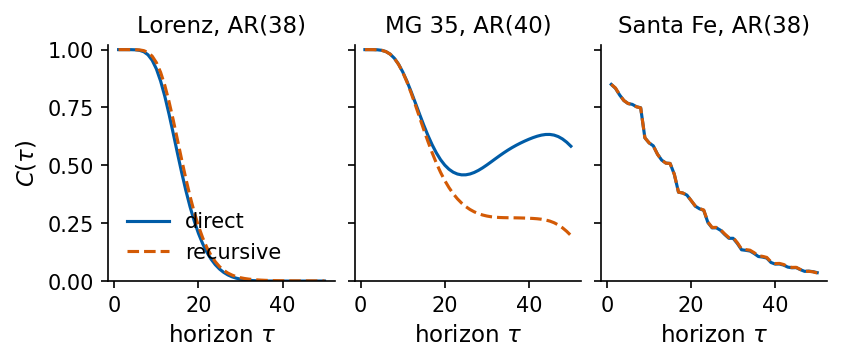

In [25]:
def ar_features(s, origins, L, stride=1):
    """Linear features: the delay vector u_k (the intercept is handled by ridge_fit)."""
    return delay_vectors(s, origins, L, stride)

def fit_direct(feature_fn, s, hp, lam, fit_orig, eval_orig):
    """Direct forecasting: one ridge readout per horizon tau, all fitted at once (columns of Y)."""
    W, b = ridge_fit(jnp.asarray(feature_fn(s, fit_orig, *hp)), jnp.asarray(target_matrix(s, fit_orig)), lam)
    return np.asarray(ridge_predict(jnp.asarray(feature_fn(s, eval_orig, *hp)), W, b))

# direct vs recursive with the same AR(p_AIC) inputs and (almost) no regularisation
for name in NAMES:
    s, p = sig[name], AR_FIT[name]["p"]
    RES[name]["AR dir (p_AIC)"] = evaluate(fit_direct(ar_features, s, (p, 1), 1e-10, ORIG_FIT, ORIG_TEST), s)
    Cd, Cr = RES[name]["AR dir (p_AIC)"]["C"], RES[name]["AR rec"]["C"]
    print(f"{name:9s} AR({p:2d})  C_tot direct {c_tot(Cd):6.2f}   recursive {c_tot(Cr):6.2f}   "
          f"C(50) direct {Cd[-1]:.3f}  recursive {Cr[-1]:.3f}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.3), layout="constrained", sharey=True)
    for ax, name in zip(axs, ["Lorenz", "MG 35", "Santa Fe"]):
        ax.plot(TAUS, RES[name]["AR dir (p_AIC)"]["C"], color=UJBlue, label="direct")
        ax.plot(TAUS, RES[name]["AR rec"]["C"], color=DSOrange, ls="--", label="recursive")
        ax.set_title(f"{name}, AR({AR_FIT[name]['p']})"); ax.set_xlabel("horizon $\\tau$")
        ax.set_ylim(0, 1.02)
    axs[0].set_ylabel("$C(\\tau)$"); axs[0].legend(loc="lower left")
    save(fig, "fig_ar_direct_vs_recursive"); plt.show()

With the same inputs the direct forecast is better on the Mackey–Glass signals ($C_{\rm tot}$ 44.4 against 38.2 on MG 15 and 33.0 against 24.6 on MG 35), and the two are close on Lorenz (15.7 direct, 16.4 recursive) and Santa Fe (16.25 and 16.31). Least squares makes each direct map the best linear predictor of $s_{k+\tau}$ from the window on the training data, while the recursive forecast relaxes towards the mean as the modes of the iterated model decay. On Lorenz and Santa Fe both linear forecasts lose the signal within about 20 steps, and the strategy matters little there.

For the final comparison we choose the window length $L$ and the ridge strength $\lambda$ of the direct AR model on the validation block, by the largest $C_{\rm tot}$.

In [26]:
AR_L_GRID = [1, 2, 4, 8, 12, 16, 24, 32, 48, 64]
LAM_GRID = [1e-8, 1e-6, 1e-4, 1e-2, 1.0]

def select_direct(feature_fn, s, hp_grid, lam_grid):
    """Choose hyperparameters and ridge strength by C_tot on the validation block."""
    best = None
    for hp in hp_grid:
        Xf = jnp.asarray(feature_fn(s, ORIG_FIT_VAL, *hp)); Yf = jnp.asarray(target_matrix(s, ORIG_FIT_VAL))
        Xv = jnp.asarray(feature_fn(s, ORIG_VAL, *hp))
        for lam in lam_grid:
            W, b = ridge_fit(Xf, Yf, lam)
            ct = c_tot(evaluate(np.asarray(ridge_predict(Xv, W, b)), s, ORIG_VAL)["C"])
            if best is None or ct > best[0]:
                best = (ct, hp, lam)
    return best

AR_DIR = {}
for name, s in sig.items():
    ct_val, hp, lam = select_direct(ar_features, s, [(L, 1) for L in AR_L_GRID], LAM_GRID)
    AR_DIR[name] = dict(L=hp[0], lam=lam, ct_val=ct_val)
    RES[name]["AR dir"] = evaluate(fit_direct(ar_features, s, hp, lam, ORIG_FIT, ORIG_TEST), s)
    print(f"{name:9s} direct AR: L = {hp[0]:2d}, lambda = {lam:.0e}, validation C_tot {ct_val:6.2f}, "
          f"test C_tot {c_tot(RES[name]['AR dir']['C']):6.2f}")
nums["ar_direct_L"] = {n: AR_DIR[n]["L"] for n in NAMES}

Lorenz    direct AR: L = 12, lambda = 1e-08, validation C_tot  17.06, test C_tot  15.33
MG 15     direct AR: L = 64, lambda = 1e-08, validation C_tot  49.80, test C_tot  49.81
MG 25     direct AR: L = 64, lambda = 1e-08, validation C_tot  27.55, test C_tot  32.56
MG 35     direct AR: L = 64, lambda = 1e-08, validation C_tot  32.35, test C_tot  38.68
Santa Fe  direct AR: L = 64, lambda = 1e+00, validation C_tot  15.66, test C_tot  16.76


The validation selects the longest window of the grid, $L=64$, on the Mackey–Glass signals and Santa Fe, and $L=12$ on Lorenz.

<hr/>
## 8. Nonlinear vector autoregression

### Feature map

A linear map of the window cannot represent a nonlinear return map. The Volterra series is the general expansion of a causal nonlinear system with fading memory, whose output depends only on present and past inputs and less and less on inputs further in the past, into multilinear terms of its past inputs [V. Volterra, *Theory of Functionals and of Integral and Integro-Differential Equations*, Dover (1959)], and finite Volterra series approximate any continuous fading-memory system uniformly [S. Boyd and L. O. Chua, IEEE Trans. Circuits Syst. **32**, 1150 (1985), [doi:10.1109/TCS.1985.1085649](https://doi.org/10.1109/TCS.1985.1085649)]. Truncated at second order on a window of past values, it becomes the nonlinear vector autoregression (NVAR) of Gauthier *et al.* [D. J. Gauthier, E. Bollt, A. Griffith and W. A. S. Barbosa, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. The window has $L$ entries spaced by a stride $\kappa$,

$$\mathbf u_k = (s_k,\ s_{k-\kappa},\ \dots,\ s_{k-(L-1)\kappa}),$$

and the feature vector contains a constant, the window and all its quadratic monomials,

$$\varphi(\mathbf u_k) = \big(1,\ u_1,\dots,u_L,\ u_1^2,\ u_1u_2,\ \dots,\ u_L^2\big), \qquad d = 1 + L + \frac{L(L+1)}{2}.$$

The prediction is linear in the features, $\hat s_{k+\tau} = \mathbf w_\tau^\top \varphi(\mathbf u_k) + b_\tau$, so training is again a ridge regression. The nonlinearity sits entirely in the fixed features. Gauthier *et al.* train a one-step model and iterate it. For the direct forecasts we fit one readout $\mathbf w_\tau$ for each horizon, from the same features.

In [27]:
def nvar_features(s, origins, L, stride):
    """NVAR features without the constant: linear part u_k (L entries) and all quadratic monomials
    u_i u_j with i <= j (L(L+1)/2 entries). With the intercept of ridge_fit: d = 1 + L + L(L+1)/2."""
    U = delay_vectors(s, origins, L, stride)
    i, j = np.triu_indices(L)                       # pairs i <= j
    return np.concatenate([U, U[:, i] * U[:, j]], axis=1)

def nvar_dim(L):
    return 1 + L + L * (L + 1) // 2

F = nvar_features(sig["Lorenz"], ORIG_FIT, 3, 2)
assert F.shape == (len(ORIG_FIT), nvar_dim(3) - 1)
print("L = 3: features per origin (without the constant):", F.shape[1], "| d =", nvar_dim(3))
for L in (4, 8, 16, 24):
    print(f"L = {L:2d}: d = {nvar_dim(L)}")

# ridge readout: JAX closed form against scikit-learn Ridge (same objective, unpenalised intercept)
Xr, Yr = nvar_features(sig["Santa Fe"], ORIG_FIT, 8, 1), target_matrix(sig["Santa Fe"], ORIG_FIT)
W, b = ridge_fit(jnp.asarray(Xr), jnp.asarray(Yr), 1e-4)
sk = Ridge(alpha=1e-4, fit_intercept=True, solver="cholesky").fit(Xr, Yr)
nums["ridge_max_diff_sklearn"] = float(max(np.abs(np.asarray(W) - sk.coef_.T).max(), np.abs(np.asarray(b) - sk.intercept_).max()))
print(f"NVAR L=8 on Santa Fe, lambda=1e-4: max |JAX - sklearn Ridge| over weights and intercepts = "
      f"{nums['ridge_max_diff_sklearn']:.1e}")

L = 3: features per origin (without the constant): 9 | d = 10
L =  4: d = 15
L =  8: d = 45
L = 16: d = 153
L = 24: d = 325
NVAR L=8 on Santa Fe, lambda=1e-4: max |JAX - sklearn Ridge| over weights and intercepts = 3.3e-11


The feature count grows quadratically with $L$, from 15 at $L=4$ to 325 at $L=24$. Our ridge solution agrees with `sklearn.linear_model.Ridge`, which minimises the same objective, to about $10^{-10}$.

### NVAR with ReservoirPy

ReservoirPy provides the feature map as the node `NVAR(delay, order, strides)`, where `delay` is our $L$ and `strides` our $\kappa$, and the readout as the node `Ridge(ridge=λ)`, which centres the features and leaves the intercept unpenalised, as ours does. The operator `>>` connects the two nodes into a model, and `fit` discards the first `warmup` time steps, during which the internal window of the NVAR node is still being filled. We use the same window, ridge strength, fitting origins and 50 target columns as in the JAX version.

In [28]:
from reservoirpy.nodes import NVAR, Ridge as RpyRidge

s = sig["Santa Fe"]
L_c, st_c, lam_c = 4, 2, 1e-4                               # one setting, used by both implementations
# feature vectors: ReservoirPy NVAR (linear part + unique quadratic monomials, no constant)
F_rpy = NVAR(delay=L_c, order=2, strides=st_c).run(s[:, None])          # row k = features at time k
F_jax = nvar_features(s, ORIG_TEST, L_c, st_c)
print("feature dimension: ReservoirPy", F_rpy.shape[1], "| ours", F_jax.shape[1])
print("max |feature difference| on the test origins:", np.abs(F_rpy[ORIG_TEST] - F_jax).max())

# full model NVAR >> Ridge, fitted on the same origins and targets (one output column per horizon)
model = NVAR(delay=L_c, order=2, strides=st_c) >> RpyRidge(ridge=lam_c)
model.fit(s[:ORIG_FIT[-1] + 1, None], target_matrix(s, np.arange(ORIG_FIT[-1] + 1)), warmup=K0)
P_rpy = model.run(s[:, None])[ORIG_TEST]                   # predictions made at the test origins
P_jax = fit_direct(nvar_features, s, (L_c, st_c), lam_c, ORIG_FIT, ORIG_TEST)
nums["rpy_max_pred_diff"] = float(np.abs(P_rpy - P_jax).max())
print(f"max |prediction difference| over {len(ORIG_TEST)} origins and 50 horizons: {nums['rpy_max_pred_diff']:.1e}")

feature dimension: ReservoirPy 14 | ours 14
max |feature difference| on the test origins: 0.0
max |prediction difference| over 950 origins and 50 horizons: 3.3e-13


The feature vectors coincide to the last digit, including the order of the monomials, and the predictions agree to about $10^{-13}$.

In the feature map for $L=3$ each input feeds its own linear feature (blue) and the quadratic features that contain it (orange). Every feature is connected to every readout, and only these connections are trained.

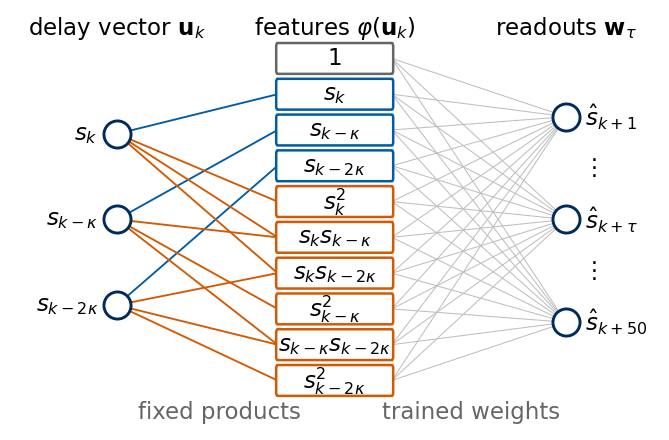

In [29]:
def draw_nvar_diagram(width=5.5, height=3.5):
    """Nodes-and-edges drawing of the NVAR feature map for L = 3 delays with stride κ.
    Left column: delay vector u_k. Middle: features (constant, linear, quadratic monomials).
    Right: one linear readout per horizon. Edges into a monomial come from its factors; the
    readout edges (all features to each output) carry the trained weights W_tau."""
    L = 3
    inputs = ["$s_k$", r"$s_{k-\kappa}$", r"$s_{k-2\kappa}$"]
    pairs = [(i, j) for i in range(L) for j in range(i, L)]                 # quadratic monomials, i <= j
    short = ["s_k", r"s_{k-\kappa}", r"s_{k-2\kappa}"]
    feats = ["$1$"] + inputs + [f"${short[i]}{short[j]}$" if i != j else f"${short[i]}^2$" for i, j in pairs]
    outs = ["$\\hat s_{k+1}$", "$\\hat s_{k+\\tau}$", "$\\hat s_{k+50}$"]
    x_in, x_f, x_out = 0.0, 1.6, 3.3
    y_in = np.linspace(0.75, 0.25, L)                         # input node heights
    y_f = np.linspace(0.97, 0.03, len(feats))                 # feature node heights
    y_out = np.array([0.8, 0.5, 0.2])
    with mpl.rc_context(SLIDE_RC):
        fig, ax = plt.subplots(figsize=(width, height))
        ax.set_xlim(-0.75, 3.95); ax.set_ylim(-0.1, 1.08); ax.axis("off")
        bw = 0.42                                                  # half width of a feature box
        # edges input -> feature: linear features copy one input, quadratic ones multiply two inputs
        for f in range(1, 1 + L):
            ax.plot([x_in, x_f - bw], [y_in[f - 1], y_f[f]], color=UJBlue, lw=0.9, zorder=1)
        for n, (i, j) in enumerate(pairs):
            for src in {i, j}:
                ax.plot([x_in, x_f - bw], [y_in[src], y_f[1 + L + n]], color=DSOrange, lw=0.9, zorder=1)
        # readout edges: every feature to every output (trained weights)
        for yf in y_f:
            for yo in y_out:
                ax.plot([x_f + bw, x_out], [yf, yo], color="0.75", lw=0.5, zorder=0)
        # nodes
        for y, lab in zip(y_in, inputs):
            ax.plot(x_in, y, "o", ms=13, mfc="white", mec=UJNavy, mew=1.4, zorder=3)   # round in any aspect
            ax.text(x_in - 0.14, y, lab, ha="right", va="center")
        for n, (y, lab) in enumerate(zip(y_f, feats)):
            col = "0.4" if n == 0 else (UJBlue if n <= L else DSOrange)
            ax.add_patch(FancyBboxPatch((x_f - bw, y - 0.035), 2 * bw, 0.07, boxstyle="round,pad=0.01",
                                        fc="white", ec=col, lw=1.2, zorder=3))
            ax.text(x_f, y, lab, ha="center", va="center", zorder=4)
        for y, lab in zip(y_out, outs):
            ax.plot(x_out, y, "o", ms=13, mfc="white", mec=UJNavy, mew=1.4, zorder=3)
            ax.text(x_out + 0.14, y, lab, ha="left", va="center")
        ax.text(x_out + 0.12, 0.65, "$\\vdots$", ha="left", va="center"); ax.text(x_out + 0.12, 0.35, "$\\vdots$", ha="left", va="center")
        # column captions
        ax.text(x_in, 1.04, "delay vector $\\mathbf{u}_k$", ha="center")
        ax.text(x_f, 1.04, "features $\\varphi(\\mathbf{u}_k)$", ha="center")
        ax.text(x_out, 1.04, "readouts $\\mathbf{w}_\\tau$", ha="center")
        ax.text(0.75, -0.08, "fixed products", ha="center", color="0.4")
        ax.text(2.6, -0.08, "trained weights", ha="center", color="0.4")
    return fig

fig = draw_nvar_diagram()
save(fig, "fig_nvar_diagram"); plt.show()

### Overfitting and regularisation

The model-selection fit uses 2190 training windows. With $L=40$ the NVAR has $d=861$ features, and least squares can fit much of the training block, noise and peculiarities included. The ridge penalty limits the size of the weights. We scan $\lambda$ for several window lengths (stride 1) on Santa Fe and compare $C_{\rm tot}$ on the training windows, where the model was fitted, with $C_{\rm tot}$ on the validation block.

L =  8 (d =  45): training C_tot from 19.9 to 27.4; validation C_tot best 25.10 at lambda = 1e-04, at lambda = 1e-10: 25.05
L = 16 (d = 153): training C_tot from 24.9 to 36.3; validation C_tot best 30.39 at lambda = 1e-02, at lambda = 1e-10: 29.24
L = 24 (d = 325): training C_tot from 28.8 to 41.3; validation C_tot best 33.09 at lambda = 1e-02, at lambda = 1e-10: 23.96
L = 32 (d = 561): training C_tot from 31.8 to 44.4; validation C_tot best 35.00 at lambda = 1e-02, at lambda = 1e-10: 12.74
L = 40 (d = 861): training C_tot from 34.2 to 46.8; validation C_tot best 36.28 at lambda = 1e-02, at lambda = 1e-10: 5.66


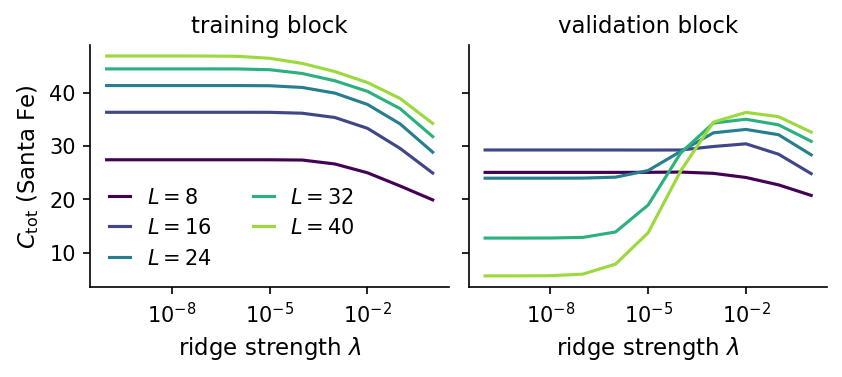

In [30]:
# validation C_tot of NVAR (stride 1) on Santa Fe as a function of lambda, for several window lengths L;
# the training-block C_tot is computed on the fitting origins themselves
s = sig["Santa Fe"]
L_SHOW, LAM_SCAN = [8, 16, 24, 32, 40], np.logspace(-10, 0, 11)
REG = {}
for L in L_SHOW:
    Xf = jnp.asarray(nvar_features(s, ORIG_FIT_VAL, L, 1)); Yf = jnp.asarray(target_matrix(s, ORIG_FIT_VAL))
    Xv = jnp.asarray(nvar_features(s, ORIG_VAL, L, 1))
    tr_, va_ = [], []
    for lam in LAM_SCAN:
        W, b = ridge_fit(Xf, Yf, lam)
        tr_.append(c_tot(evaluate(np.asarray(ridge_predict(Xf, W, b)), s, ORIG_FIT_VAL)["C"]))
        va_.append(c_tot(evaluate(np.asarray(ridge_predict(Xv, W, b)), s, ORIG_VAL)["C"]))
    REG[L] = (np.array(tr_), np.array(va_))
    print(f"L = {L:2d} (d = {nvar_dim(L):3d}): training C_tot from {min(tr_):.1f} to {max(tr_):.1f}; "
          f"validation C_tot best {max(va_):.2f} at lambda = {LAM_SCAN[int(np.argmax(va_))]:.0e}, "
          f"at lambda = 1e-10: {va_[0]:.2f}")
nums["nvar_reg_santafe"] = {str(L): {"val_best": float(REG[L][1].max()), "val_lam_min": float(REG[L][1][0]),
                                     "train_lam_min": float(REG[L][0][0])} for L in L_SHOW}

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained", sharey=True)
    for j, L in enumerate(L_SHOW):
        col = plt.get_cmap("viridis")(j / (len(L_SHOW) - 1) * 0.85)
        axs[0].plot(LAM_SCAN, REG[L][0], color=col, label=f"$L={L}$")
        axs[1].plot(LAM_SCAN, REG[L][1], color=col)
    for ax, title in zip(axs, ["training block", "validation block"]):
        ax.set(xscale="log", xlabel="ridge strength $\\lambda$", title=title)
    axs[0].set_ylabel("$C_{\\rm tot}$ (Santa Fe)"); axs[0].legend(loc="lower left", ncol=2, handlelength=1.0)
    save(fig, "fig_nvar_regularisation"); plt.show()

On the training windows $C_{\rm tot}$ grows with $L$ and falls as $\lambda$ grows, as expected for least squares with more parameters and less penalty. On the validation block the picture changes with the window length. For $L=8$ the penalty hardly matters (25.05 at $\lambda=10^{-10}$, 25.10 at best). For $L=40$ the nearly unregularised model reaches 46.8 on the training windows and only 5.7 on the validation block, and $\lambda=10^{-2}$ raises the validation score to 36.3, the best of the scan. Large feature sets are useful only together with regularisation, and $\lambda$ must be chosen together with $L$. We therefore choose $L$, $T$ and $\lambda$ jointly on the validation block for every signal, from $L\in\{2,\dots,32\}$, $T\in\{1,2,4,8\}$ and $\lambda\in\{10^{-8},\dots,1\}$.

In [31]:
NVAR_L_GRID, NVAR_STRIDE_GRID = [2, 3, 4, 6, 8, 12, 16, 24, 32], [1, 2, 4, 8]
NVAR_LAM_GRID = [1e-8, 1e-6, 1e-4, 1e-2, 1.0]
NVAR_SEL = {}
t0 = time.time()
for name, s in sig.items():
    ct_val, hp, lam = select_direct(nvar_features, s, list(itertools.product(NVAR_L_GRID, NVAR_STRIDE_GRID)),
                                    NVAR_LAM_GRID)
    NVAR_SEL[name] = dict(L=hp[0], stride=hp[1], lam=lam, d=nvar_dim(hp[0]), ct_val=ct_val)
    RES[name]["NVAR"] = evaluate(fit_direct(nvar_features, s, hp, lam, ORIG_FIT, ORIG_TEST), s)
    print(f"{name:9s} NVAR: L = {hp[0]:2d}, stride = {hp[1]}, lambda = {lam:.0e}, d = {nvar_dim(hp[0]):3d}, "
          f"validation C_tot {ct_val:6.2f}, test C_tot {c_tot(RES[name]['NVAR']['C']):6.2f}")
print(f"selection over {len(NVAR_L_GRID) * len(NVAR_STRIDE_GRID) * len(NVAR_LAM_GRID)} settings per signal "
      f"in {time.time() - t0:.0f} s")
nums["nvar_sel"] = {n: {k: (float(v) if k in ("lam", "ct_val") else int(v)) for k, v in NVAR_SEL[n].items()}
                    for n in NAMES}

Lorenz    NVAR: L = 16, stride = 1, lambda = 1e-08, d = 153, validation C_tot  17.89, test C_tot  15.33
MG 15     NVAR: L = 32, stride = 4, lambda = 1e-08, d = 561, validation C_tot  50.00, test C_tot  50.00
MG 25     NVAR: L = 32, stride = 2, lambda = 1e-08, d = 561, validation C_tot  46.23, test C_tot  44.72
MG 35     NVAR: L = 32, stride = 1, lambda = 1e-08, d = 561, validation C_tot  48.14, test C_tot  48.72
Santa Fe  NVAR: L = 32, stride = 2, lambda = 1e-02, d = 561, validation C_tot  36.57, test C_tot  33.69
selection over 180 settings per signal in 14 s


The selection picks $L=32$, the largest window of the grid, on the Mackey–Glass signals and Santa Fe, and $L=16$ with stride 1 on Lorenz. A longer window might do slightly better on these signals. The test $C_{\rm tot}$ is close to the validation value on the Mackey–Glass signals and lower by 2.9 on Santa Fe and by 2.6 on Lorenz, partly because the test block contains different stretches of the signal and partly because the selection itself adapts to the validation block.

### One-step forecasts of each model

Before comparing whole capacity curves we look at the simplest task, the forecast one step ahead, $\tau=1$, on Santa Fe and on Mackey–Glass at the three delays. For each model the upper panels show the target $s_{k+1}$ (black) and the forecast $\hat s_{k+1}$ (dashed) on the first 100 test targets, and the lower panels show $\hat s_{k+1}$ against $s_{k+1}$ on all 950 test targets. A perfect forecast puts all points on the diagonal. The AR and NVAR models are the direct models selected on the validation block in Sections 7 and 8. The MA model is fitted by maximum likelihood with the order $q\in\{2,4,8\}$ of smallest AIC, the ARMA model is the one selected in Section 6, and both compute their one-step forecasts with the Kalman filter from all values up to $s_k$, with the parameters fitted on the training block.

model               Santa Fe                 MG 15                 MG 25                 MG 35    (C and 1 - C at tau = 1, test block)
AR       C=0.8497 1-C=1.5e-01   C=1.0000 1-C=4.6e-07   C=1.0000 1-C=5.3e-07   C=1.0000 1-C=4.2e-07
MA       C=0.7761 1-C=2.2e-01   C=1.0000 1-C=1.6e-05   C=1.0000 1-C=1.4e-05   C=1.0000 1-C=1.0e-05
ARMA     C=0.8387 1-C=1.6e-01   C=1.0000 1-C=1.5e-06   C=1.0000 1-C=7.4e-07   C=1.0000 1-C=6.0e-07
NVAR     C=0.9663 1-C=3.4e-02   C=1.0000 1-C=1.9e-12   C=1.0000 1-C=5.6e-06   C=1.0000 1-C=1.5e-07
MA orders chosen by AIC: {'Santa Fe': 8, 'MG 15': 8, 'MG 25': 8, 'MG 35': 8}


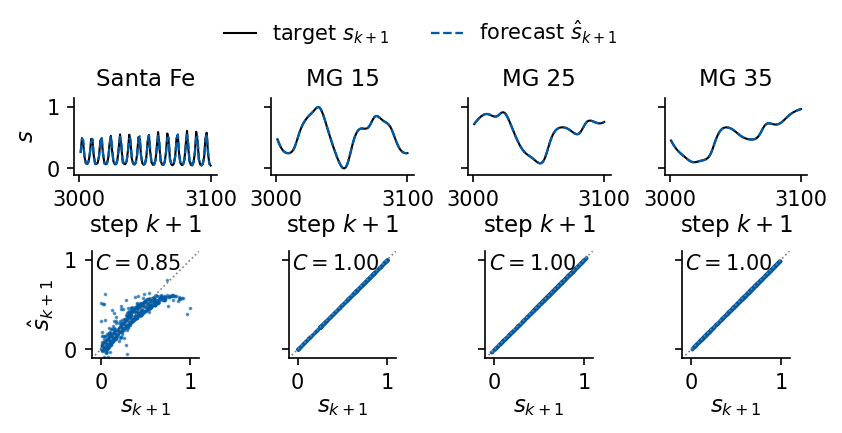

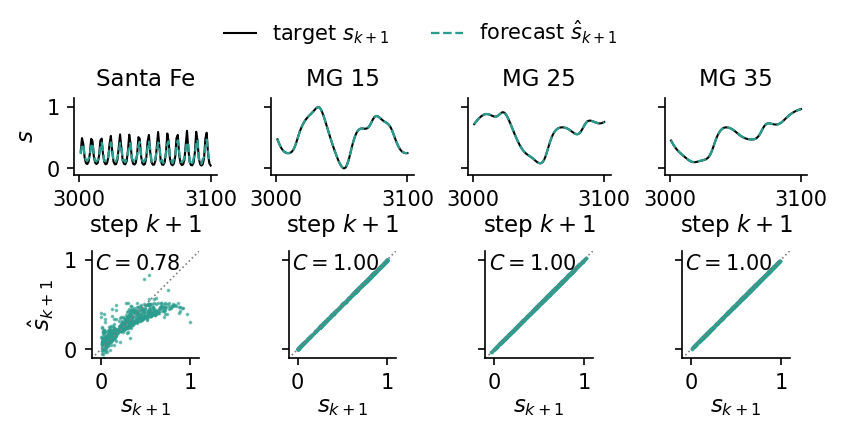

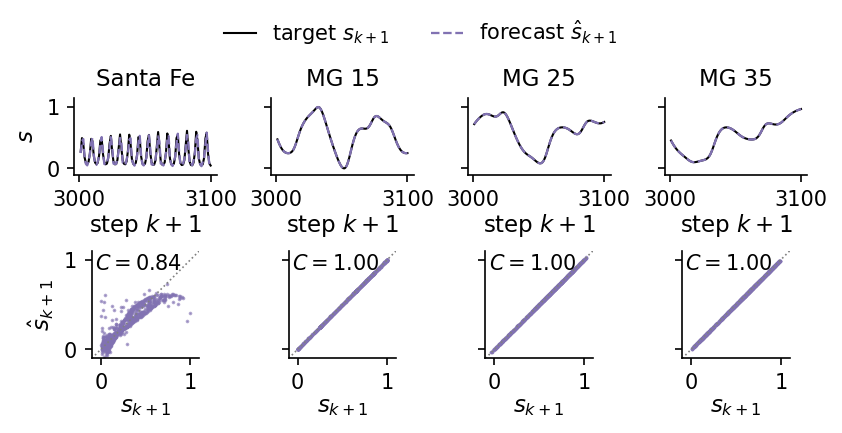

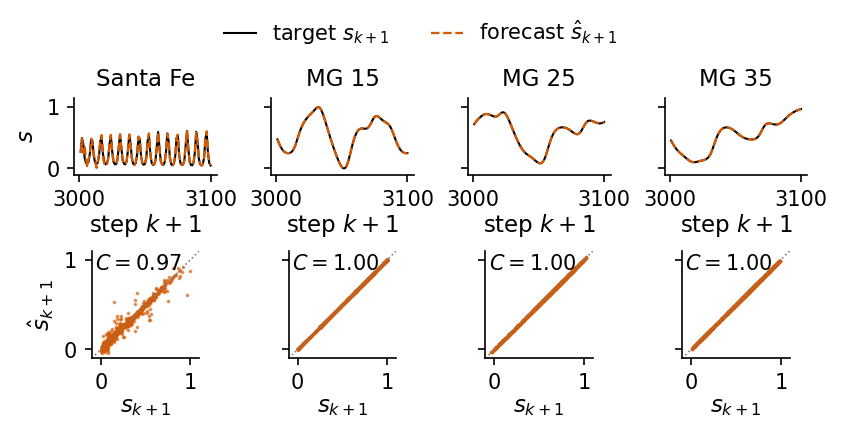

In [32]:
# one-step forecasts (tau = 1) on the test block for Santa Fe and Mackey-Glass at the three delays, one figure per model
OS_NAMES = ["Santa Fe", "MG 15", "MG 25", "MG 35"]
MA_Q_GRID = [2, 4, 8]

def fit_ma(s_train, q):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ARIMA(s_train, order=(0, 0, q), trend="c").fit(method_kwargs={"maxiter": 200})

jobs_ma = [(name, q) for name in OS_NAMES for q in MA_Q_GRID]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    fits_ma = Parallel(n_jobs=8)(delayed(fit_ma)(sig[name][:N_TRAIN], q) for name, q in jobs_ma)
MA_FIT = {}
for name in OS_NAMES:
    cands = [(res.aic, q, res) for (n_, q), res in zip(jobs_ma, fits_ma) if n_ == name]
    MA_FIT[name] = min(cands, key=lambda c: c[0])[1:]

def one_step_state_space(res, s):
    """One-step predictions of a fitted statsmodels model over the whole record with the fitted parameters
    (Kalman filter), returned at the test targets s_{k+1}, k in ORIG_TEST."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pred = res.apply(s).fittedvalues
    return np.asarray(pred)[ORIG_TEST + 1]

ONE = {}
for name in OS_NAMES:
    s = sig[name]
    ONE[(name, "AR")] = fit_direct(ar_features, s, (AR_DIR[name]["L"], 1), AR_DIR[name]["lam"], ORIG_FIT, ORIG_TEST)[:, 0]
    ONE[(name, "MA")] = one_step_state_space(MA_FIT[name][1], s)
    ONE[(name, "ARMA")] = one_step_state_space(FITS[(name, ARMA_SEL[(name, 0)])], s)
    nv = NVAR_SEL[name]
    ONE[(name, "NVAR")] = fit_direct(nvar_features, s, (nv["L"], nv["stride"]), nv["lam"], ORIG_FIT, ORIG_TEST)[:, 0]

MODEL_TXT = {"AR": lambda n: f"AR, $L={AR_DIR[n]['L']}$", "MA": lambda n: f"MA({MA_FIT[n][0]})",
             "ARMA": lambda n: "ARMA({},{})".format(ARMA_SEL[(n, 0)][0], ARMA_SEL[(n, 0)][2]),
             "NVAR": lambda n: f"NVAR, $L={NVAR_SEL[n]['L']}$"}
MODEL_COL = {"AR": UJBlue, "MA": "#2A9D8F", "ARMA": "#8172B2", "NVAR": DSOrange}
nums["one_step"] = {}
print(f"{'model':6s}" + "".join(f"{n:>22s}" for n in OS_NAMES) + "    (C and 1 - C at tau = 1, test block)")
for m in ["AR", "MA", "ARMA", "NVAR"]:
    row = ""
    for name in OS_NAMES:
        y_t = sig[name][ORIG_TEST + 1]
        sc = scores(jnp.asarray(ONE[(name, m)]), jnp.asarray(y_t))
        Cv, rv = float(sc["C"]), float(sc["r"])
        nums["one_step"][f"{m} {name}"] = {"C": Cv, "r": rv}
        row += f"   C={Cv:.4f} 1-C={1 - Cv:.1e}"
    print(f"{m:6s}{row}")
print("MA orders chosen by AIC:", {n: MA_FIT[n][0] for n in OS_NAMES})

K_SHOW = 100                                              # first 100 test targets in the time panels
for m in ["AR", "MA", "ARMA", "NVAR"]:
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(2, 4, figsize=(5.5, 2.8), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.4]})
        for c_, name in enumerate(OS_NAMES):
            a_t, a_s = axs[0, c_], axs[1, c_]
            y_t = sig[name][ORIG_TEST + 1]; y_p = ONE[(name, m)]
            kk = ORIG_TEST[:K_SHOW] + 1
            a_t.plot(kk, y_t[:K_SHOW], color="k", lw=1.0, label="target $s_{k+1}$")
            a_t.plot(kk, y_p[:K_SHOW], "--", color=MODEL_COL[m], lw=1.1, label=r"forecast $\hat s_{k+1}$")
            a_t.set_title(name); a_t.set_ylim(-0.1, 1.15); a_t.set_yticks([0, 1]); a_t.set_xticks([3000, 3100])
            a_t.set_xlabel("step $k+1$", labelpad=1)
            a_s.plot(y_t, y_p, ".", ms=1.5, color=MODEL_COL[m], alpha=0.6)
            a_s.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.8, ls=":")
            a_s.set_xlim(-0.1, 1.1); a_s.set_ylim(-0.1, 1.1); a_s.set_aspect("equal")
            a_s.set_xticks([0, 1]); a_s.set_yticks([0, 1]); a_s.set_xlabel("$s_{k+1}$", labelpad=1)
            v = nums["one_step"][f"{m} {name}"]
            a_s.text(0.03, 0.97, f"$C={v['C']:.2f}$", transform=a_s.transAxes, va="top", ha="left", fontsize=10)
            if c_ > 0:
                a_t.set_yticklabels([]); a_s.set_yticklabels([])
        axs[0, 0].set_ylabel("$s$"); axs[1, 0].set_ylabel(r"$\hat s_{k+1}$")
        fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, fontsize=10, handlelength=1.5)
        save(fig, f"fig_onestep_{m.lower()}"); plt.show()


The one-step forecasts hide how the three models behave further ahead. For every horizon $\tau$ we use the direct AR readout, and for MA and ARMA the fitted one-step model iterated $\tau$ times with the future innovations set to zero. The top panel of each figure overlays the forecasts at $\tau=1,5,10$ on the Santa Fe record, and the bottom panel gives $C(\tau)$ for the four signals. An MA($q$) model has no memory of the values themselves, so beyond $q$ steps its forecast is the mean.

AR {'Santa Fe': 0.597, 'MG 15': 0.984, 'MG 25': 0.883, 'MG 35': 0.914} (C at tau = 10)
MA {'Santa Fe': 0.0, 'MG 15': 0.0, 'MG 25': 0.0, 'MG 35': 0.0} (C at tau = 10)
ARMA {'Santa Fe': 0.562, 'MG 15': 0.846, 'MG 25': 0.836, 'MG 35': 0.867} (C at tau = 10)


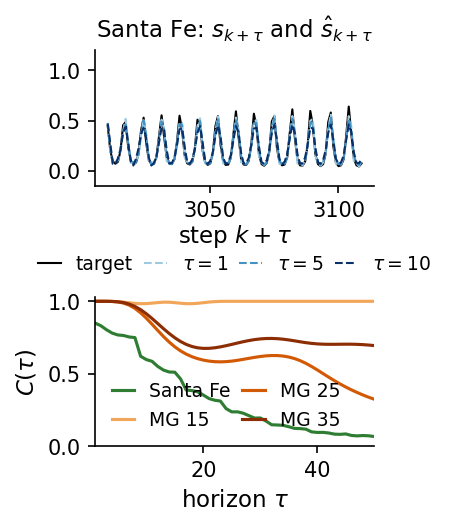

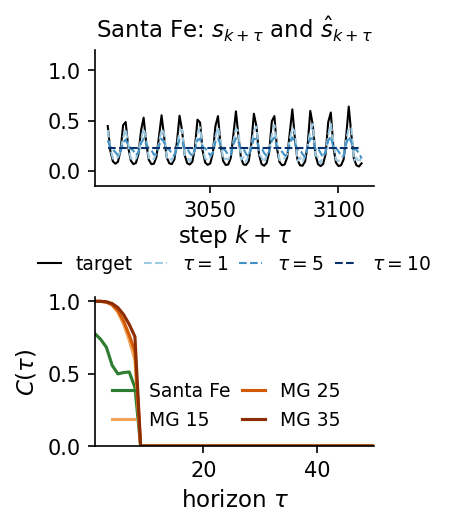

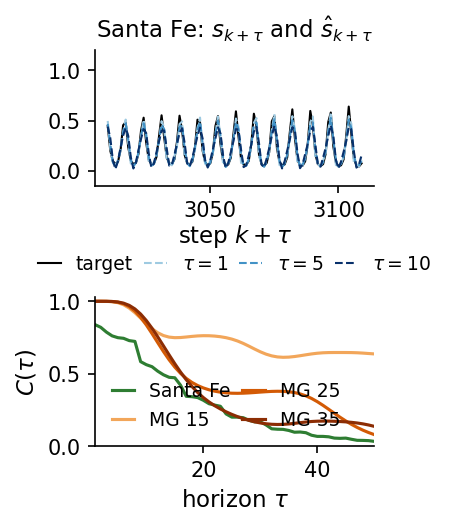

In [33]:
# tau-step forecasts of AR (direct), MA and ARMA (both iterated), one figure per model:
# top, Santa Fe targets and forecasts at three horizons; bottom, C(tau) for the four signals
TAU_SHOW = [1, 5, 10]
TAU_COL = {1: "#9ecae1", 5: "#4292c6", 10: "#08306b"}
SIG_COL = {"Santa Fe": "#2E7D32", "MG 15": "#F2A65A", "MG 25": DSOrange, "MG 35": "#8C2D04"}

def ma_recursive(name):
    """tau-step forecasts of the AIC-selected MA(q): innovations from the Kalman filter, future ones set to zero."""
    q, res = MA_FIT[name]
    full = res.apply(sig[name])
    return recursive_forecast(sig[name], ORIG_TEST, [], res.maparams, mu=res.params[0], resid=np.asarray(full.resid))

TAU_PRED = {}
for name in OS_NAMES:
    s = sig[name]
    TAU_PRED[(name, "AR")] = fit_direct(ar_features, s, (AR_DIR[name]["L"], 1), AR_DIR[name]["lam"], ORIG_FIT, ORIG_TEST)
    TAU_PRED[(name, "MA")] = ma_recursive(name)
    TAU_PRED[(name, "ARMA")] = statsmodels_recursive(name, ARMA_SEL[(name, 0)])[0]
nums["tau_ahead"] = {}
for m in ["AR", "MA", "ARMA"]:
    for name in OS_NAMES:
        C = evaluate(TAU_PRED[(name, m)], sig[name])["C"]
        nums["tau_ahead"][f"{m} {name}"] = {"C1": float(C[0]), "C10": float(C[9]), "C50": float(C[-1])}
    print(m, {n: round(nums["tau_ahead"][f"{m} {n}"]["C10"], 3) for n in OS_NAMES}, "(C at tau = 10)")

K_TAU = 100
for m in ["AR", "MA", "ARMA"]:
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(2, 1, figsize=(2.9, 3.4), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.1]})
        s = sig["Santa Fe"]; P = TAU_PRED[("Santa Fe", m)]
        t0 = ORIG_TEST[0] + 10
        axs[0].plot(np.arange(t0, t0 + K_TAU), s[t0:t0 + K_TAU], color="k", lw=1.0, label="target")
        for tau in TAU_SHOW:
            idx = np.arange(10 - tau, 10 - tau + K_TAU)            # origins whose target k + tau lies in the window
            axs[0].plot(ORIG_TEST[idx] + tau, P[idx, tau - 1], "--", color=TAU_COL[tau], lw=1.0, label=fr"$\tau={tau}$")
        axs[0].set_title("Santa Fe: $s_{k+\\tau}$ and $\\hat s_{k+\\tau}$")
        axs[0].set_ylim(-0.15, 1.2); axs[0].set_xlabel("step $k+\\tau$", labelpad=1)
        axs[0].legend(ncol=4, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.38), handlelength=1.2, columnspacing=0.6)
        for name in OS_NAMES:
            axs[1].plot(TAUS, evaluate(TAU_PRED[(name, m)], sig[name])["C"], color=SIG_COL[name], label=name)
        axs[1].set_ylim(0, 1.03); axs[1].set_xlim(1, TAU_MAX)
        axs[1].set_xlabel("horizon $\\tau$"); axs[1].set_ylabel(r"$C(\tau)$")
        axs[1].legend(fontsize=9, ncol=2, loc="lower left", handlelength=1.2, columnspacing=0.6)
        save(fig, f"fig_tau_ahead_{m.lower()}"); plt.show()


We show the same two views for NVAR, the direct forecast with the window, stride and ridge strength selected on the validation block. The time panel shows the Santa Fe test targets with the forecasts five and ten steps ahead next to the one-step forecast, and the lower panel follows the capacity $C(\tau)$ over all horizons for the four signals, to be compared with the curves of the direct AR model.

NVAR {'Santa Fe': 0.918, 'MG 15': 1.0, 'MG 25': 0.998, 'MG 35': 0.999} (C at tau = 5)
NVAR {'Santa Fe': 0.851, 'MG 15': 1.0, 'MG 25': 0.983, 'MG 35': 0.986} (C at tau = 10)


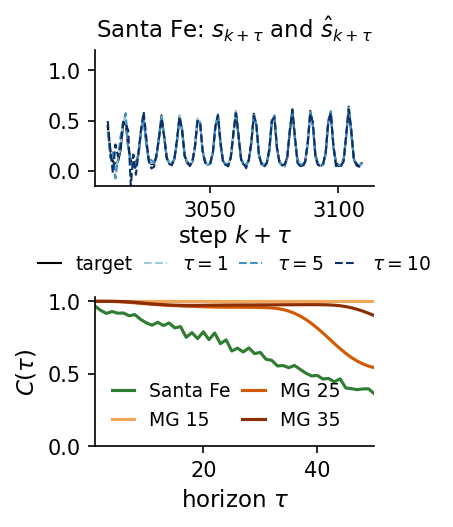

In [34]:
# tau-step forecasts of NVAR (direct), same layout as the AR, MA and ARMA figures
for name in OS_NAMES:
    nv = NVAR_SEL[name]
    TAU_PRED[(name, "NVAR")] = fit_direct(nvar_features, sig[name], (nv["L"], nv["stride"]), nv["lam"], ORIG_FIT, ORIG_TEST)
    C = evaluate(TAU_PRED[(name, "NVAR")], sig[name])["C"]
    nums["tau_ahead"][f"NVAR {name}"] = {"C1": float(C[0]), "C5": float(C[4]), "C10": float(C[9]), "C50": float(C[-1])}
print("NVAR", {n: round(nums["tau_ahead"][f"NVAR {n}"]["C5"], 3) for n in OS_NAMES}, "(C at tau = 5)")
print("NVAR", {n: round(nums["tau_ahead"][f"NVAR {n}"]["C10"], 3) for n in OS_NAMES}, "(C at tau = 10)")

m = "NVAR"
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(2.9, 3.4), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.1]})
    s = sig["Santa Fe"]; P = TAU_PRED[("Santa Fe", m)]
    t0 = ORIG_TEST[0] + 10
    axs[0].plot(np.arange(t0, t0 + K_TAU), s[t0:t0 + K_TAU], color="k", lw=1.0, label="target")
    for tau in TAU_SHOW:
        idx = np.arange(10 - tau, 10 - tau + K_TAU)
        axs[0].plot(ORIG_TEST[idx] + tau, P[idx, tau - 1], "--", color=TAU_COL[tau], lw=1.0, label=fr"$\tau={tau}$")
    axs[0].set_title("Santa Fe: $s_{k+\\tau}$ and $\\hat s_{k+\\tau}$")
    axs[0].set_ylim(-0.15, 1.2); axs[0].set_xlabel("step $k+\\tau$", labelpad=1)
    axs[0].legend(ncol=4, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.38), handlelength=1.2, columnspacing=0.6)
    for name in OS_NAMES:
        axs[1].plot(TAUS, evaluate(TAU_PRED[(name, m)], sig[name])["C"], color=SIG_COL[name], label=name)
    axs[1].set_ylim(0, 1.03); axs[1].set_xlim(1, TAU_MAX)
    axs[1].set_xlabel("horizon $\\tau$"); axs[1].set_ylabel(r"$C(\tau)$")
    axs[1].legend(fontsize=9, ncol=2, loc="lower left", handlelength=1.2, columnspacing=0.6)
    save(fig, "fig_tau_ahead_nvar"); plt.show()

A wider view of the same NVAR forecasts on the Santa Fe test block shows how the forecast follows the pulses and the collapses at one, five and ten steps ahead, with the capacity of each horizon written in its panel.

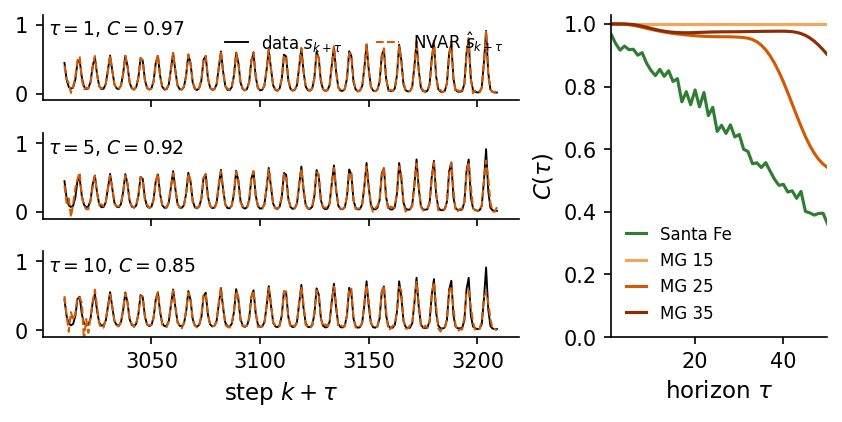

In [35]:
# NVAR on the Santa Fe test block at three horizons (left) and C(tau) for the four signals (right)
s = sig["Santa Fe"]; P = TAU_PRED[("Santa Fe", "NVAR")]
K_WIDE = 200
t0 = ORIG_TEST[0] + 10
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.7), layout="constrained")
    gs = fig.add_gridspec(3, 2, width_ratios=[2.2, 1.0])
    for r_, tau in enumerate(TAU_SHOW):
        ax = fig.add_subplot(gs[r_, 0])
        idx = np.arange(10 - tau, 10 - tau + K_WIDE)
        ax.plot(np.arange(t0, t0 + K_WIDE), s[t0:t0 + K_WIDE], color="k", lw=0.9, label="data $s_{k+\\tau}$")
        ax.plot(ORIG_TEST[idx] + tau, P[idx, tau - 1], "--", color=DSOrange, lw=1.0, label="NVAR $\\hat s_{k+\\tau}$")
        Cv = float(evaluate(P, s)["C"][tau - 1])
        ax.text(0.01, 0.95, fr"$\tau={tau}$, $C={Cv:.2f}$", transform=ax.transAxes, va="top", fontsize=9,
                bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
        ax.set_ylim(-0.1, 1.15); ax.set_yticks([0, 1])
        if r_ < 2:
            ax.set_xticklabels([])
        else:
            ax.set_xlabel("step $k+\\tau$")
        if r_ == 0:
            ax.legend(ncol=2, fontsize=8, loc="upper right", handlelength=1.4)
    axc = fig.add_subplot(gs[:, 1])
    for name in OS_NAMES:
        axc.plot(TAUS, evaluate(TAU_PRED[(name, "NVAR")], sig[name])["C"], color=SIG_COL[name], label=name)
    axc.set_ylim(0, 1.03); axc.set_xlim(1, TAU_MAX)
    axc.set_xlabel("horizon $\\tau$"); axc.set_ylabel(r"$C(\tau)$")
    axc.legend(fontsize=8, loc="lower left", handlelength=1.2)
    save(fig, "fig_nvar_santafe_tau"); plt.show()

At one step all four models forecast the Mackey–Glass signals almost perfectly, with $C=1.0000$ to four digits, and they differ only in the unexplained fraction $1-C$, which lies between $2\times10^{-12}$ and $2\times10^{-5}$. With unit sampling a smooth signal changes little in one step, and any model with access to a few past values extrapolates it. The MA model selects the largest order of the grid, $q=8$, on all four signals. Its Kalman filter reconstructs the innovations from all past values, so it uses the whole past as well, and it has the largest $1-C$ of the four models on Mackey–Glass. On Santa Fe the linear models reach $C\approx0.78$–$0.85$ and bend away from the diagonal at high intensities, where the laser collapses, while NVAR reaches $C\approx0.97$. The differences on Mackey–Glass appear at larger horizons, in the capacity curves of Section 9.

<hr/>
## 9. All models on all signals

We collect the test capacities of persistence, the direct AR model, the recursive AR, ARMA and ARIMA models and the direct NVAR model. The table lists $C_{\rm tot}$ with $\tau_{1/2}$ in brackets (">50" means that $C$ stays above 0.5 up to $\tau = 50$).

In [36]:
MODELS = ["persistence", "AR dir", "AR rec", "ARMA rec", "ARIMA rec", "NVAR"]
LABELS = {"persistence": "persistence", "AR dir": "AR (direct)", "AR rec": "AR (recursive)",
          "ARMA rec": "ARMA (recursive)", "ARIMA rec": "ARIMA (recursive)", "NVAR": "NVAR (direct)"}
STYLE = {"persistence": dict(color="0.55", ls=":"), "AR dir": dict(color=UJBlue),
         "AR rec": dict(color=UJBlue, ls="--"), "ARMA rec": dict(color="#2A9D8F", ls="--"),
         "ARIMA rec": dict(color="#8172B2", ls="-."), "NVAR": dict(color=DSOrange)}
print("C_tot (sum of C(tau), tau = 1..50) on the test block; tau_1/2 in brackets")
print(f"{'model':18s}" + "".join(f"{n:>15s}" for n in NAMES))
for m in MODELS:
    row = "".join(f"{c_tot(RES[n][m]['C']):8.2f} ({fmt_tau_half(RES[n][m]['C']):>3s})" for n in NAMES)
    print(f"{LABELS[m]:18s}{row}")
    for n in NAMES:
        nums["Ctot"][n][m] = c_tot(RES[n][m]["C"])
        nums["tau_half"][n][m] = tau_half(RES[n][m]["C"])
print("\nC(1) / C(10) on the test block")
for m in MODELS:
    print(f"{LABELS[m]:18s}" + "".join(f"    {RES[n][m]['C'][0]:.4f}/{RES[n][m]['C'][9]:.3f}" for n in NAMES))
print("\npart of C_tot from horizons with r(tau) < 0 (listed where it exceeds 0.1)")
for m in MODELS:
    for n in NAMES:
        neg = c_tot(RES[n][m]["C"][RES[n][m]["r"] < 0])
        nums.setdefault("Ctot_negative_r", {}).setdefault(n, {})[m] = neg
        if neg > 0.1:
            print(f"  {LABELS[m]:18s} {n:9s} {neg:5.2f} of {c_tot(RES[n][m]['C']):5.2f}, "
                  f"smallest r = {RES[n][m]['r'].min():+.3f} at tau = {int(np.argmin(RES[n][m]['r'])) + 1}")

C_tot (sum of C(tau), tau = 1..50) on the test block; tau_1/2 in brackets
model                      Lorenz          MG 15          MG 25          MG 35       Santa Fe
persistence           8.35 (  8)   19.54 (  6)   13.26 (  8)   11.85 ( 10)    5.45 (  1)
AR (direct)          15.33 ( 16)   49.81 (>50)   32.56 ( 42)   38.68 (>50)   16.76 ( 16)
AR (recursive)       16.38 ( 17)   38.22 (>50)   29.33 ( 35)   24.61 ( 19)   16.31 ( 16)
ARMA (recursive)     15.10 ( 16)   37.11 (>50)   24.12 ( 17)   20.62 ( 17)   15.27 ( 13)
ARIMA (recursive)    15.26 ( 16)   22.48 ( 13)   15.82 ( 14)   17.15 ( 16)   15.83 ( 15)
NVAR (direct)        15.33 ( 16)   50.00 (>50)   44.72 (>50)   48.72 (>50)   33.69 ( 39)

C(1) / C(10) on the test block
persistence           0.9878/0.339    0.9761/0.016    0.9866/0.258    0.9909/0.431    0.2690/0.098
AR (direct)           1.0000/0.892    1.0000/0.984    1.0000/0.883    1.0000/0.914    0.8497/0.597
AR (recursive)        1.0000/0.944    1.0000/0.892    1.0000/0.878  

Every fitted model beats persistence on every signal. Among the linear models the direct AR model has the largest $C_{\rm tot}$ on the Mackey–Glass signals and Santa Fe, and the recursive AR model on Lorenz. The recursive ARMA and ARIMA models are not better than the recursive AR model on any signal. Their extra MA terms describe correlated noise, which these deterministic signals do not have, and ARIMA's differencing removes a trend that is not there and adds a unit root that the forecasts carry along. NVAR gives the largest $C_{\rm tot}$ on the Mackey–Glass signals and Santa Fe (33.7 against 16.8 for the direct AR model). On Lorenz all models reach $\tau_{1/2}$ of 16 or 17 samples, and NVAR does not improve on the linear models over these horizons. The recursive ARIMA forecasts on MG 25 and MG 35 become anticorrelated with the target at the longest horizons, and these horizons contribute 2.25 and 1.99 to their $C_{\rm tot}$, as the negative swings of $\rho(\tau)$ do for persistence.

saved 60 arrays


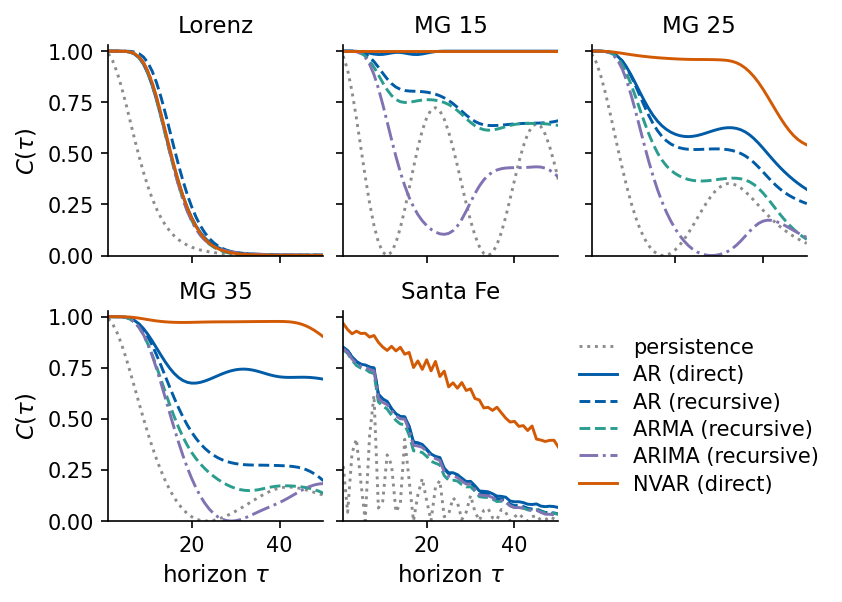

In [37]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.9), layout="constrained", sharex=True, sharey=True)
    for ax, name in zip(axs.flat, NAMES):
        for m in MODELS:
            ax.plot(TAUS, RES[name][m]["C"], lw=1.4, label=LABELS[m], **STYLE[m])
        ax.set_title(name); ax.set_ylim(0, 1.03); ax.set_xlim(1, TAU_MAX)
    for ax in axs[1]:
        ax.set_xlabel("horizon $\\tau$")
    for ax in axs[:, 0]:
        ax.set_ylabel("$C(\\tau)$")
    leg_ax = axs.flat[-1]; leg_ax.axis("off")
    h, l = axs.flat[0].get_legend_handles_labels()
    leg_ax.legend(h, l, loc="center", handlelength=1.8, labelspacing=0.35)
    save(fig, "fig_linear_capacity"); plt.show()

# C(tau) arrays for the comparison with recurrent networks
arrays = {"tau": TAUS, "signals": np.array(NAMES), "models": np.array(MODELS)}
for n in NAMES:
    for m in MODELS:
        key = f"{n}__{m}".replace(" ", "_")
        arrays["C__" + key] = RES[n][m]["C"]
        arrays["r__" + key] = RES[n][m]["r"]
np.savez(f"{OUT}/capacity_lab034.npz", **arrays)
print("saved", len(arrays) - 3, "arrays")

We plot $C(\tau) = r(\tau)^2$ on the test origins for every model. On the limit cycle MG 15, the direct AR and NVAR models stay near $C=1$ for all 50 horizons, because a periodic signal is predicted by a linear filter once its period is resolved, while the recursive linear models lose part of the oscillation. On the chaotic Mackey–Glass signals NVAR keeps $C$ close to 1 far beyond the linear models. On Santa Fe NVAR doubles $C_{\rm tot}$ of the linear models, and on Lorenz all models decay within about 25 samples, 0.5 time units.

### Linear models and the folding of the Santa Fe attractor

We compare the predictions with the targets on the Santa Fe test block at $\tau = 1, 2, 5, 10$ for the direct AR model and the direct NVAR model.

{'AR_tau1': 0.85, 'AR_tau2': 0.832, 'AR_tau5': 0.768, 'AR_tau10': 0.597, 'NVAR_tau1': 0.966, 'NVAR_tau2': 0.937, 'NVAR_tau5': 0.918, 'NVAR_tau10': 0.851}


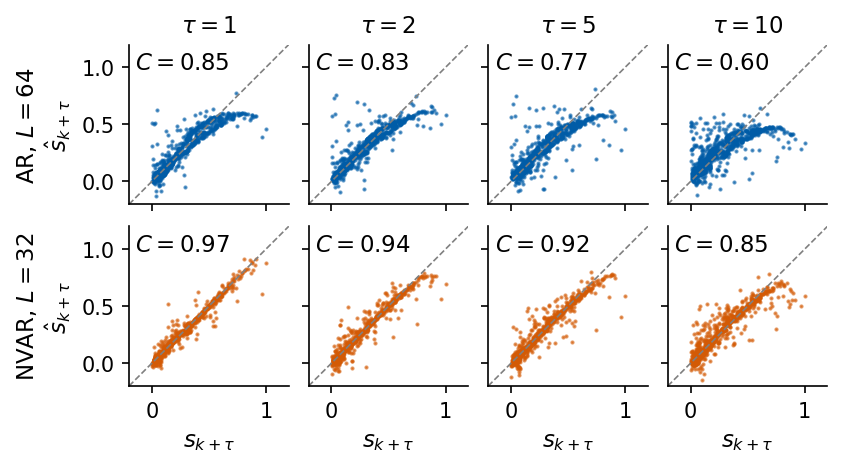

In [38]:
s = sig["Santa Fe"]
TAU_SC = [1, 2, 5, 10]
Yt = target_matrix(s, ORIG_TEST)
P_ar = fit_direct(ar_features, s, (AR_DIR["Santa Fe"]["L"], 1), AR_DIR["Santa Fe"]["lam"], ORIG_FIT, ORIG_TEST)
nv = NVAR_SEL["Santa Fe"]
P_nv = fit_direct(nvar_features, s, (nv["L"], nv["stride"]), nv["lam"], ORIG_FIT, ORIG_TEST)
nums["santafe_scatter"] = {}
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 4, figsize=(5.5, 3.0), layout="constrained", sharex=True, sharey=True)
    for row, (P, lab, col) in enumerate([(P_ar, f"AR, $L={AR_DIR['Santa Fe']['L']}$", UJBlue),
                                         (P_nv, f"NVAR, $L={nv['L']}$", DSOrange)]):
        for c, tau in enumerate(TAU_SC):
            ax = axs[row, c]
            ax.plot(Yt[:, tau - 1], P[:, tau - 1], ".", ms=2, color=col, alpha=0.6)
            ax.plot([-0.2, 1.2], [-0.2, 1.2], color="0.5", lw=0.8, ls="--")
            Cv = float(scores(jnp.asarray(P[:, tau - 1]), jnp.asarray(Yt[:, tau - 1]))["C"])
            nums["santafe_scatter"][f"{'AR' if row == 0 else 'NVAR'}_tau{tau}"] = Cv
            ax.text(0.04, 0.96, f"$C={Cv:.2f}$", transform=ax.transAxes, va="top")
            if row == 0:
                ax.set_title(f"$\\tau={tau}$")
            if row == 1:
                ax.set_xlabel("$s_{k+\\tau}$")
            ax.set_xlim(-0.2, 1.2); ax.set_ylim(-0.2, 1.2); ax.set_aspect("equal")
        axs[row, 0].set_ylabel(f"{lab}\n$\\hat s_{{k+\\tau}}$")
    save(fig, "fig_santafe_scatter_ar_nvar"); plt.show()
print({k: round(v, 3) for k, v in nums["santafe_scatter"].items()})

The AR predictions bend away from the diagonal at large intensities, so the largest pulses are underestimated, and the cloud widens with $\tau$ ($C$ falls from 0.85 to 0.60). The NVAR predictions stay close to the diagonal ($C$ from 0.97 to 0.85). The one-step return map $s_{k+1}$ against $s_k$ of the training block explains this. The same value of $s_k$ is followed by different values of $s_{k+1}$ depending on whether the intensity rises or falls, and the cloud is folded. A linear function of the window is a tilted plane through this cloud and cannot follow the fold. Quadratic features can bend the plane.

best straight line s_(k+1) = 0.108 + 0.529 s_k; rising steps 0.48 of all


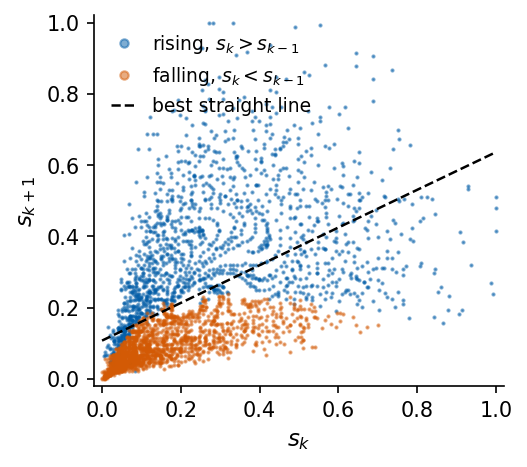

In [39]:
# one-step return map of the Santa Fe laser: s_{k+1} against s_k on the training block,
# coloured by whether the intensity was rising (s_k > s_{k-1}) or falling, with the best straight line
s = sig["Santa Fe"]
x0, x1, xm = s[1:N_TRAIN - 1], s[2:N_TRAIN], s[0:N_TRAIN - 2]
rising = x0 > xm
b1, b0 = np.polyfit(x0, x1, 1)
print(f"best straight line s_(k+1) = {b0:.3f} + {b1:.3f} s_k; rising steps {rising.mean():.2f} of all")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(3.4, 3.0), layout="constrained")
    ax.plot(x0[rising], x1[rising], ".", ms=2, color=UJBlue, alpha=0.5, label="rising, $s_k > s_{k-1}$")
    ax.plot(x0[~rising], x1[~rising], ".", ms=2, color=DSOrange, alpha=0.5, label="falling, $s_k < s_{k-1}$")
    xx = np.linspace(0, 1, 2)
    ax.plot(xx, b0 + b1 * xx, "k--", lw=1.2, label="best straight line")
    ax.set(xlabel="$s_k$", ylabel="$s_{k+1}$", xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
    ax.legend(loc="upper left", fontsize=9, markerscale=4, handlelength=1.4)
    save(fig, "fig_return_map"); plt.show()


### Free run

In a free run each model starts from the true history up to the first test origin $k_0 = 3000$ and is then iterated on its own predictions for 300 steps. The AR, ARMA and ARIMA models are iterated as in Section 6, with all future innovations set to zero. The NVAR model uses its one-step readout ($\tau = 1$) with the window, stride and $\lambda$ selected on the validation block, and every prediction is appended to its window. We plot the data and the free runs on Santa Fe and MG 25.

Santa Fe  data: mean over the 300 free-run steps 0.226
Santa Fe  AR     first 50 steps: r = +0.813, C = 0.662   mean of the last 100 steps     0.228   first step outside [-0.5, 1.5]: None
Santa Fe  ARMA   first 50 steps: r = +0.828, C = 0.686   mean of the last 100 steps     0.228   first step outside [-0.5, 1.5]: None
Santa Fe  ARIMA  first 50 steps: r = +0.875, C = 0.766   mean of the last 100 steps     0.226   first step outside [-0.5, 1.5]: None
Santa Fe  NVAR   first 50 steps: r = +0.015, C = 0.000   mean of the last 100 steps     -3.53   first step outside [-0.5, 1.5]: 5
MG 25     data: mean over the 300 free-run steps 0.598
MG 25     AR     first 50 steps: r = +0.895, C = 0.801   mean of the last 100 steps     0.589   first step outside [-0.5, 1.5]: None
MG 25     ARMA   first 50 steps: r = +0.979, C = 0.959   mean of the last 100 steps     0.597   first step outside [-0.5, 1.5]: None
MG 25     ARIMA  first 50 steps: r = +0.082, C = 0.007   mean of the last 100 steps     0.932  

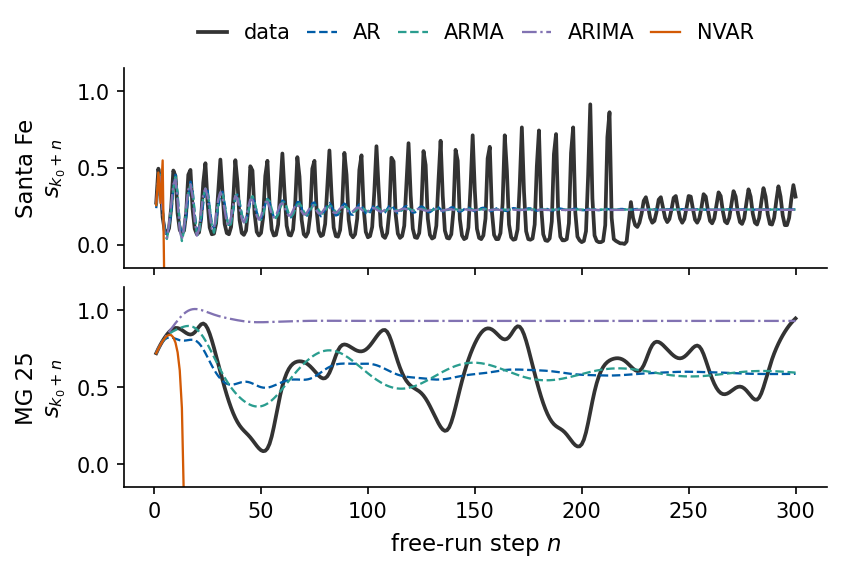

In [40]:
@partial(jax.jit, static_argnums=(3, 4, 5))
def nvar_free_run(hist, W, b, L, stride, n_steps):
    """Iterate the one-step NVAR readout, appending each prediction to the history.
    hist: the last (L-1)*stride + 1 samples, newest last. Returns the n_steps predicted samples."""
    i, j = jnp.triu_indices(L)
    def step(h, _):
        u = h[::-1][::stride][:L]                                  # (s_k, s_{k-stride}, ...)
        phi = jnp.concatenate([u, u[i] * u[j]])
        s_new = jnp.clip(phi @ W + b, -10.0, 10.0)                # clip only to keep a diverging run finite
        return jnp.concatenate([h[1:], s_new[None]]), s_new
    _, out = jax.lax.scan(step, hist, None, length=n_steps)
    return out

N_FREE, K_START = 300, N_TRAIN            # free run from the first test origin
FREE = {}
for name in ["Santa Fe", "MG 25"]:
    s = sig[name]
    org = np.array([K_START])
    a = AR_FIT[name]
    runs = {"AR": recursive_forecast(s, org, a["phi"], [], mu=a["mu"], n_steps=N_FREE)[0]}
    for d, label in ((0, "ARMA"), (1, "ARIMA")):
        order = ARMA_SEL[(name, d)]
        res = FITS[(name, order)]
        full = res.apply(s)
        mu = res.params[0] if d == 0 else 0.0
        runs[label] = recursive_forecast(s, org, res.arparams, res.maparams, mu=mu, d=d,
                                         resid=np.asarray(full.resid), n_steps=N_FREE)[0]
    nv = NVAR_SEL[name]
    L, st = nv["L"], nv["stride"]
    # one-step NVAR readout (tau = 1 column) with the selected L, stride and lambda
    W, b = ridge_fit(jnp.asarray(nvar_features(s, ORIG_FIT, L, st)), jnp.asarray(target_matrix(s, ORIG_FIT)[:, :1]),
                     nv["lam"])
    hist = jnp.asarray(s[K_START - (L - 1) * st:K_START + 1])
    runs["NVAR"] = np.asarray(nvar_free_run(hist, W[:, 0], b[0], L, st, N_FREE))
    FREE[name] = runs
    truth = s[K_START + 1:K_START + 1 + N_FREE]
    print(f"{name:9s} data: mean over the {N_FREE} free-run steps {truth.mean():.3f}")
    for m, r in runs.items():
        out_of_range = np.flatnonzero((r < -0.5) | (r > 1.5))
        exit_step = int(out_of_range[0] + 1) if out_of_range.size else None
        sc50 = {k: float(v) for k, v in scores(jnp.asarray(r[:50]), jnp.asarray(truth[:50])).items()}
        late = float(r[-100:].mean())                     # level of the run over its last 100 steps
        nums.setdefault("freerun", {}).setdefault(name, {})[m] = {"C50": sc50["C"], "r50": sc50["r"],
                                                                 "exit_step": exit_step, "late_mean": late}
        print(f"{name:9s} {m:6s} first 50 steps: r = {sc50['r']:+.3f}, C = {sc50['C']:.3f}   "
              f"mean of the last 100 steps {late:9.3g}   first step outside [-0.5, 1.5]: {exit_step}")
    nums.setdefault("freerun_nvar_exit_step", {})[name] = nums["freerun"][name]["NVAR"]["exit_step"]

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.7), layout="constrained", sharex=True)
    steps = np.arange(1, N_FREE + 1)
    fstyle = {"AR": dict(color=UJBlue, ls="--"), "ARMA": dict(color="#2A9D8F", ls="--"),
              "ARIMA": dict(color="#8172B2", ls="-."), "NVAR": dict(color=DSOrange)}
    for ax, name in zip(axs, ["Santa Fe", "MG 25"]):
        s = sig[name]
        ax.plot(steps, s[K_START + 1:K_START + 1 + N_FREE], color="0.2", lw=1.8, label="data")
        for m, r in FREE[name].items():
            r = r.copy()
            bad = np.flatnonzero((r < -0.5) | (r > 1.5))
            if bad.size:                                   # draw a diverging run only until it leaves the plot
                r[bad[0] + 1:] = np.nan
            ax.plot(steps, r, lw=1.1, label=m, **fstyle[m])
        lo_, hi_ = s[:N_TRAIN].min(), s[:N_TRAIN].max()
        ax.set_ylim(lo_ - 0.15, hi_ + 0.15); ax.set_ylabel(f"{name}\n$s_{{k_0+n}}$")
    axs[-1].set_xlabel("free-run step $n$")
    axs[0].legend(loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.32), handlelength=1.4, columnspacing=0.8)
    save(fig, "fig_freerun_linear"); plt.show()

The free runs of the linear models follow the data for a few oscillations and then relax to a constant, the mean of the iterated model, as the decaying modes of Section 5 predict. We score each run by the capacity $C$ between the run and the data over the first 50 free-run steps, and we check its level separately by the mean over its last 100 steps, because $C$ is insensitive to an offset. On Santa Fe the three linear runs reach $C$ between 0.66 and 0.77, and all three settle at a level between 0.226 and 0.228, while the data average 0.226 over the 300 steps. On MG 25 the ARMA run follows the data best ($C=0.96$) and the AR run reaches $C=0.80$, and both settle close to the data mean of 0.598 (at 0.597 and 0.589). The ARIMA run, which has a unit root, loses the oscillation at once ($C=0.01$) and settles at 0.93, far above the data. The one-step NVAR model, which gives the best direct forecasts, is unstable in free run. It leaves the interval $[-0.5, 1.5]$ at step 5 on Santa Fe and at step 15 on MG 25, and its capacity over the first 50 steps is below 0.01 on both signals. A one-step error moves the window off the attractor, where the quadratic features were never trained, and the polynomial map amplifies the deviation. Gauthier *et al.* obtain stable NVAR free runs on Lorenz with the full three-dimensional state as input and a one-step model of the increments. With a scalar signal and the settings selected for direct forecasting, stability in free run is not guaranteed, and it has to be checked and, if needed, selected for separately, for example by a stronger penalty or a shorter window.


<hr/>
## Forecast accuracy and stability

A forecast predicts $s_{k+\tau}$ from a window of past values, either directly with one map per horizon or recursively by iterating a one-step map. The data are split in time order into training, validation and test blocks, with the rescaling fitted on the training data, because a shuffled split puts test targets into the training inputs. Each forecast is scored by the capacity $C=r^2$, the squared Pearson correlation between forecast and target, summarised by $C_{\rm tot}$ and the skill horizon $\tau_{1/2}$. The capacity is unchanged by a rescaling and a shift of the forecast and loses the sign of $r$, so the sign and the level of a forecast are checked separately. Persistence and the training mean are the baselines that every model must beat.

The AR model is a linear regression on past values. It is fitted by least squares, it is stationary when the roots of $\Phi_p(z)$ lie outside the unit circle, and its order is chosen by AIC or by the one-step capacity on validation data, which need not agree for deterministic signals. MA terms describe correlated innovations, recognised by an ACF that vanishes beyond lag $q$, and they require an invertible model and a maximum-likelihood fit, whose convergence must be checked. Differencing in ARIMA removes trends and unit roots. Every iterated forecast of a stationary ARMA model relaxes to the mean, so recursive linear forecasts lose chaotic signals within a few oscillations, and on our signals the MA and differencing terms did not improve on the AR model.

NVAR adds the quadratic monomials of a strided window to the linear features and keeps training a single ridge regression, which we implemented in JAX and reproduced with ReservoirPy. Its feature count $1+L+L(L+1)/2$ grows quickly, so the ridge penalty must be chosen together with the window, and on the validation block it decides between overfitting and a useful model. The one-step forecasts of the AR, MA, ARMA and NVAR models are almost free of error on Mackey–Glass and already separate the models on Santa Fe, where the three linear models reach $C\approx0.78$–$0.85$ and bend away from the diagonal at high intensities, while NVAR reaches $C\approx0.97$. Direct NVAR forecasts beat all linear models on the chaotic Mackey–Glass signals and on the Santa Fe laser, where the linear models cannot follow the fold of the return map, while on Lorenz none of the models keeps $C$ above 0.5 for more than 16 samples. The same NVAR iterated as a one-step model diverges in free run, which shows that a good forecast map and a stable dynamical model are two different requirements.

### References

- G. E. P. Box, G. M. Jenkins, G. C. Reinsel and G. M. Ljung, *Time Series Analysis: Forecasting and Control*, 5th ed., Wiley (2015).
- P. J. Brockwell and R. A. Davis, *Introduction to Time Series and Forecasting*, Springer (2016), [doi:10.1007/978-3-319-29854-2](https://doi.org/10.1007/978-3-319-29854-2).
- H. Akaike, A new look at the statistical model identification, IEEE Trans. Autom. Control **19**, 716 (1974), [doi:10.1109/TAC.1974.1100705](https://doi.org/10.1109/TAC.1974.1100705).
- V. Volterra, *Theory of Functionals and of Integral and Integro-Differential Equations*, Dover (1959).
- S. Boyd and L. O. Chua, Fading memory and the problem of approximating nonlinear operators with Volterra series, IEEE Trans. Circuits Syst. **32**, 1150 (1985), [doi:10.1109/TCS.1985.1085649](https://doi.org/10.1109/TCS.1985.1085649).
- D. J. Gauthier, E. Bollt, A. Griffith and W. A. S. Barbosa, Next generation reservoir computing, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2).
- H. Kantz and T. Schreiber, *Nonlinear Time Series Analysis*, 2nd ed., Cambridge University Press (2003).
- N. Trouvain, L. Pedrelli, T. T. Dinh and X. Hinaut, ReservoirPy: an efficient and user-friendly library to design echo state networks, ICANN 2020, [doi:10.1007/978-3-030-61616-8_40](https://doi.org/10.1007/978-3-030-61616-8_40).

In [41]:
nums["runtime_s"] = round(time.time() - t_start, 1)

def to_json(o):
    if isinstance(o, dict):
        return {str(k): to_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_json(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
with open(f"{OUT}/numbers_lab034.json", "w") as fh:
    json.dump(to_json(nums), fh, indent=1)

# LaTeX macros for the slides; names contain letters only
SIG_TEX = {"Lorenz": "Lorenz", "MG 15": "MGfifteen", "MG 25": "MGtwentyfive", "MG 35": "MGthirtyfive",
           "Santa Fe": "SantaFe"}
MOD_TEX = {"persistence": "Pers", "AR dir": "ARdir", "AR rec": "ARrec", "ARMA rec": "ARMArec",
           "ARIMA rec": "ARIMArec", "NVAR": "NVAR"}
macros = {}
for n in NAMES:
    S = SIG_TEX[n]
    for m in MODELS:
        macros[f"Ctot{MOD_TEX[m]}{S}"] = f"{nums['Ctot'][n][m]:.1f}"
        th = nums["tau_half"][n][m]
        macros[f"tauhalf{MOD_TEX[m]}{S}"] = f"{{>}}{TAU_MAX}" if th is None else str(th)
    macros[f"ARpAIC{S}"] = str(nums["ar_p_aic"][n])
    macros[f"ARpVal{S}"] = str(nums["ar_p_val"][n])
    macros[f"ARdirL{S}"] = str(nums["ar_direct_L"][n])
    macros[f"ARMAorder{S}"] = "({},{},{})".format(*nums["arma_order"][n])
    macros[f"ARIMAorder{S}"] = "({},{},{})".format(*nums["arima_order"][n])
    nv = nums["nvar_sel"][n]
    macros[f"NVARL{S}"], macros[f"NVARstride{S}"], macros[f"NVARd{S}"] = str(nv["L"]), str(nv["stride"]), str(nv["d"])
    e = int(np.round(np.log10(nv["lam"])))
    macros[f"NVARlam{S}"] = f"10^{{{e}}}"
    macros[f"ARminRoot{S}"] = f"{nums['ar_min_root'][n]:.3f}"
for n in ["Santa Fe", "MG 25"]:
    for m in ["AR", "ARMA", "ARIMA"]:
        macros[f"freeC{m}{SIG_TEX[n]}"] = f"{nums['freerun'][n][m]['C50']:.2f}"
    macros[f"freeNVARexit{SIG_TEX[n]}"] = str(nums["freerun_nvar_exit_step"][n])
macros["ARMAfailures"] = str(len(failed))
for k, v in nums["santafe_scatter"].items():
    m, tau = k.split("_tau")
    macros[f"scatterC{m}{['one', 'two', 'five', 'ten'][[1, 2, 5, 10].index(int(tau))]}"] = f"{v:.2f}"
macros["demoScaledC"] = f"{nums['demo_scaled']['C']:.2f}"
macros["demoScaledR"] = f"{nums['demo_scaled']['r']:+.2f}"
macros["demoAntiR"] = f"{nums['demo_anti']['r']:+.2f}"
macros["demoNoisyC"] = f"{nums['demo_noisy']['C']:.2f}"
macros["leakFracShuffled"] = f"{nums['leak_frac_shuffled']:.3f}"
macros["maRhoOne"] = f"{nums['ma2_rho1_exact']:.3f}"
macros["maRhoTwo"] = f"{nums['ma2_rho2_exact']:.3f}"
with open(f"{OUT}/nb_numbers_lab034.tex", "w") as fh:
    for k, v in macros.items():
        assert k.isalpha(), k
        fh.write(f"\\newcommand{{\\labthreefour{k}}}{{{v}}}\n")
print(len(macros), "macros written; runtime", nums["runtime_s"], "s")

134 macros written; runtime 354.7 s
